# **EDA de Resistencias Antimicrobianas**

## 1. Introducción. Pregunta de la investigación

La resistencia a los antimicrobianos (RAM) constituye uno de los principales retos actuales de salud pública, debido a su creciente impacto sobre la eficacia de los tratamientos y el manejo de las enfermedades infecciosas. Su aparición y propagación están relacionadas con múltiples factores, entre ellos el uso de antimicrobianos y las características clínicas y epidemiológicas de los pacientes. Por ello, resulta fundamental identificar los grupos de población y los contextos asistenciales en los que se observa una mayor prevalencia de microorganismos no sensibles. Este análisis pretende estudiar la relación entre los factores demográficos, socioeconómicos y clínicos y la presencia de resistencia antimicrobiana. Los resultados pueden contribuir a comprender mejor su distribución epidemiológica e identificar posibles grupos prioritarios para las estrategias de vigilancia y prevención.

**¿Qué factores clínicos, demográficos, hospitalarios y socioeconómicos están más asociados a la aparición de resistencia antimicrobiana (AMR) en los cultivos positivos? ¿Qué bacterias son las más resistentes? ¿ A qué antibióticos?**


## 2. Carga de datos 

Primero importamos las librerias que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import sys
from pathlib import Path
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path.cwd().parent))


Cargamos los dataset. Están en formato .csv separados por ",": Seleccionamos las columnas con las que trabajar y cambiamos los nombres de las columnas. Los datos son públicos, proporcionados por la Universidad de Stanford.

In [2]:

# Carga individual de cada archivo en una sola línea

cohort = pd.read_csv('../data/cohort.csv', sep=',', usecols=['anon_id', 'pat_enc_csn_id_coded',
                                                             'order_proc_id_coded','ordering_mode', 
                                                             'culture_description','was_positive',
                                                               'organism', 'antibiotic', 'susceptibility'], 
                                                               na_values=['Null'])
demographics = pd.read_csv('../data/demographics.csv', sep=',',usecols=['anon_id', 'pat_enc_csn_id_coded', 
                                                                      'order_proc_id_coded', 'age','gender'],
                                                                      na_values=['Null'])
resistance = pd.read_csv('../data/microbial_resistance.csv', sep=',',  usecols=['anon_id', 'pat_enc_csn_id_coded', 
                                                                               'order_proc_id_coded',
                                                                               'organism', 'antibiotic',
                                                                               'resistant_time_to_culturetime'], na_values=['Null'])
ward = pd.read_csv('../data/ward_info.csv', sep=',', usecols=['anon_id', 'pat_enc_csn_id_coded', 'order_proc_id_coded',
                                                            'hosp_ward_IP', 'hosp_ward_OP',
                                                             'hosp_ward_ER', 'hosp_ward_ICU'], na_values=['Null'])
adi = pd.read_csv('../data/adi_scores.csv', sep=',', usecols=['anon_id', 'pat_enc_csn_id_coded', 'order_proc_id_coded',
                                                              'adi_score', 'adi_state_rank'], na_values=['Null'])


In [3]:
# Renombrar IDs
for df in [cohort, demographics, resistance, ward, adi]:
    df.rename(columns={
        'order_proc_id_coded': 'culture_id',
        'pat_enc_csn_id_coded': 'episode_id'
    }, inplace=True)

# Renombrar las variables de ward
ward.rename(columns={
    'hosp_ward_IP': 'IP',
    'hosp_ward_OP': 'OP',
    'hosp_ward_ER': 'ER',
    'hosp_ward_ICU': 'ICU'
}, inplace=True)

Decidimos que columnas nos interesan para nuestro EDA:

Todas estan unidas por un ``anon_id``, ``episode_id``y ``culture_id``. Que utilizaremos para unir los diferentes dataframes.

* **Cohort**: ordering_mode, culture_description, was_positive, organism, antibiotic, susceptibility
* **Demographics**: age, gender
* **Resistance**: organism, antibiotic, resistant_time_to_culturetime (days)
* **Ward**: hosp_ward_IP, hosp_ward_OP,hosp_ward_ER, hosp_ward_ICU
* **ADI**: adi_score, adi_state_rank

Definiciones relevantes: 

- **Unidad de análisis:** un cultivo (`culture_id`).
- **Población:** cultivos con `was_positive == True` y al menos un resultado de sensibilidad.
- **AMR:** el cultivo tiene al menos un antibiótico con `susceptibility == Resistant`. Los "Intermediate" se excluyen con la posibilidad de analizarse aparte.
- **`resistant_time_to_culturetime`:** días entre la confirmación de una resistencia previa y la orden del cultivo. Es un **predictor** (historial), nunca el desenlace.

## 3. Calidad de los datos

Vamos a revisar los datos que tenemos: nulos, ID_huerfanos, duplicados y que tipos de variables tenemos

In [4]:
#Tipo de variables y tamaño

tables = {
    "cohort": cohort,
    "demographics": demographics,
    "resistance": resistance,
    "ward": ward,
    "adi": adi,
}

for name, df in tables.items():
    print("Filas x columnas:", df.shape)
    print(f"Memoria: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
    print(df.dtypes.to_frame("dtype"))


Filas x columnas: (2241050, 9)
Memoria: 800.9 MB
                     dtype
anon_id                str
episode_id           int64
culture_id           int64
ordering_mode          str
culture_description    str
was_positive         int64
organism               str
antibiotic             str
susceptibility         str
Filas x columnas: (751075, 5)
Memoria: 106.3 MB
              dtype
anon_id         str
episode_id    int64
culture_id    int64
age             str
gender      float64
Filas x columnas: (2161648, 6)
Memoria: 458.9 MB
                               dtype
anon_id                          str
episode_id                     int64
culture_id                     int64
organism                         str
antibiotic                       str
resistant_time_to_culturetime  int64
Filas x columnas: (751075, 7)
Memoria: 79.4 MB
            dtype
anon_id       str
episode_id  int64
culture_id  int64
IP          int64
OP          int64
ER          int64
ICU         int64
Filas x column

In [5]:
#NAs

for name, df in tables.items():
    null = pd.DataFrame({
        "n_null": df.isna().sum(),
        "%_null": (df.isna().mean() * 100).round(2),
    })
    print(f"\n===== Nulos: {name} =====")
    print(null)
 


===== Nulos: cohort =====
                     n_null  %_null
anon_id                   0    0.00
episode_id                0    0.00
culture_id                0    0.00
ordering_mode         73042    3.26
culture_description       0    0.00
was_positive              0    0.00
organism             632308   28.21
antibiotic           632308   28.21
susceptibility       634468   28.31

===== Nulos: demographics =====
            n_null  %_null
anon_id          0    0.00
episode_id       0    0.00
culture_id       0    0.00
age              0    0.00
gender         120    0.02

===== Nulos: resistance =====
                               n_null  %_null
anon_id                             0     0.0
episode_id                          0     0.0
culture_id                          0     0.0
organism                            0     0.0
antibiotic                          0     0.0
resistant_time_to_culturetime       0     0.0

===== Nulos: ward =====
            n_null  %_null
anon_id      

In [6]:
#Duplicados

print("\n===== Duplicados: filas completamente idénticas =====")
for nombre, df in tables.items():
    print(f"{nombre}: {df.duplicated().sum():,} ({df.duplicated().mean() * 100:.2f}%)")
 
# Granularidad: filas por cultivo.
# Esperado: demographics, ward y adi -> 1 fila por cultivo.
#           cohort y resistance -> varias (organismo x antibiótico).
print("\n===== Filas por cultivo =====")
for nombre, df in tables.items():
    n = df.groupby("culture_id").size()
    print(f"\n{nombre}:")
    print(n.describe().round(2).to_frame("filas_por_cultivo").T)
    print("Cultivos con más de 1 fila:", (n > 1).sum())





===== Duplicados: filas completamente idénticas =====
cohort: 0 (0.00%)
demographics: 0 (0.00%)
resistance: 0 (0.00%)
ward: 0 (0.00%)
adi: 0 (0.00%)

===== Filas por cultivo =====

cohort:
                      count  mean   std  min  25%  50%  75%   max
filas_por_cultivo  751075.0  2.98  5.19  1.0  1.0  1.0  1.0  75.0
Cultivos con más de 1 fila: 118463

demographics:
                      count  mean  std  min  25%  50%  75%  max
filas_por_cultivo  751075.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
Cultivos con más de 1 fila: 0

resistance:
                      count   mean   std  min  25%  50%   75%    max
filas_por_cultivo  166537.0  12.98  29.1  1.0  2.0  4.0  11.0  483.0
Cultivos con más de 1 fila: 131521

ward:
                      count  mean  std  min  25%  50%  75%  max
filas_por_cultivo  751075.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
Cultivos con más de 1 fila: 0

adi:
                      count  mean  std  min  25%  50%  75%  max
filas_por_cultivo  751075.0   1.0  0.0  1.0  1.0 

131.521 de los 166.537 cultivos tienen varias filas (media 13, máximo 483). Esas filas no son duplicados, son resistencias previas distintas (organismo × antibiótico), y por eso las agregamos a una fila por cultivo.

In [7]:
# ---------------------------------------------------------------
# IDs únicos por tabla
# ---------------------------------------------------------------

IDS = ["anon_id", "culture_id", "episode_id"]
resumen_ids = pd.DataFrame(
    {nombre: {col: df[col].nunique() for col in IDS} for nombre, df in tables.items()}
).T
print("\n===== IDs únicos por tabla =====")
print(resumen_ids)
 
# ---------------------------------------------------------------
# 5. IDs huérfanos (id_culture) respecto a cohort
# ---------------------------------------------------------------
base = set(cohort["culture_id"].unique())
filas = []
for nombre, df in tables.items():
    if nombre == "cohort":
        continue
    ids = set(df["culture_id"].unique())
    filas.append({
        "tabla": nombre,
        "en_tabla_no_en_cohort": len(ids - base),
        "en_cohort_no_en_tabla": len(base - ids),
        "en_comun": len(ids & base),
    })
print("\n===== Huérfanos de id_culture frente a cohort =====")
print(pd.DataFrame(filas).set_index("tabla"))
 
# Lo mismo con anon_id
base_p = set(cohort["anon_id"].unique())
filas = []
for nombre, df in tables.items():
    if nombre == "cohort":
        continue
    ids = set(df["anon_id"].unique())
    filas.append({
        "tabla": nombre,
        "en_tabla_no_en_cohort": len(ids - base_p),
        "en_cohort_no_en_tabla": len(base_p - ids),
    })
print("\n===== Huérfanos de anon_id frente a cohort =====")
print(pd.DataFrame(filas).set_index("tabla"))
 
# ---------------------------------------------------------------
# 6. Consistencia de IDs: ¿cada id_culture pertenece a un único paciente
#    y a un único episodio, en todas las tablas?
# ---------------------------------------------------------------
print("\n===== Consistencia id_culture -> anon_id / id_enc =====")
for nombre, df in tables.items():
    n_pac = df.groupby("culture_id")["anon_id"].nunique()
    n_enc = df.groupby("culture_id")["episode_id"].nunique()
    print(f"{nombre}: cultivos con >1 paciente = {(n_pac > 1).sum()}, "
          f"cultivos con >1 episodio = {(n_enc > 1).sum()}")
 
# ---------------------------------------------------------------
# 7. Valores de las variables categóricas clave
# ---------------------------------------------------------------
print("\n===== Valores categóricos =====")
print(cohort["was_positive"].value_counts(dropna=False))
print(cohort["susceptibility"].value_counts(dropna=False))
print(cohort["ordering_mode"].value_counts(dropna=False))
print(cohort["culture_description"].value_counts(dropna=False).head(15))
print(demographics["age"].value_counts(dropna=False).sort_index())
print(demographics["gender"].value_counts(dropna=False))
print(adi[["adi_score", "adi_state_rank"]].describe())
 



===== IDs únicos por tabla =====
              anon_id  culture_id  episode_id
cohort         283715      751075      574584
demographics   283715      751075      574584
resistance      32780      166537      122726
ward           283715      751075      574584
adi            283715      751075      574584

===== Huérfanos de id_culture frente a cohort =====
              en_tabla_no_en_cohort  en_cohort_no_en_tabla  en_comun
tabla                                                               
demographics                      0                      0    751075
resistance                        0                 584538    166537
ward                              0                      0    751075
adi                               0                      0    751075

===== Huérfanos de anon_id frente a cohort =====
              en_tabla_no_en_cohort  en_cohort_no_en_tabla
tabla                                                     
demographics                      0                    

### **Resumen de los datos**
- 751.075 cultivos, 283.715 pacientes y 574.584 episodios.
+ Los dataframes de demographics, ward y adi tienen exactamente los mismos números de pacientes (anon_id) que cohort .
* Consistencia perfecta: cada cultivo pertenece a un único paciente y a un único episodio en todas las tablas.
- Edad sin nulos (nueve grupos)
+ Resistance: Subcojunto de 166.537 cultivos frente a 751.075 de cohort


In [8]:
print(cohort.groupby("culture_id")["was_positive"].max().value_counts())

was_positive
0    630798
1    120277
Name: count, dtype: int64


Antes de pasar a definir nuestra cohorte de estudio, vamos a proceder a modificar dos variables para que sean más claras de entender.

In [9]:

cohort['culture_result'] = cohort['was_positive'].map({0: 'Negative', 1: 'Positive'})
resistance.rename(columns={'resistant_time_to_culturetime': 'days_to_resistance_confirmation'}, inplace=True)


## 4. Creación de la cohorte de estudio

Vamos a incluir en nuestro estudio aquellos cultivos positivos. Susceptibles y Resistentes. 

| Resultado Antibiograma | ¿AMR? | Interpretación EUCAST(2019)|
|---|---:|---|
| S | 0 | Susceptible |
| I | 0 | Susceptible con exposición aumentada |
| R | 1| Resistente |
| Synergism | excluir | No es categoría S/I/R |
| Inconclusive | excluir | Resultado no interpretable |
| Null | excluir | Sin resultado |

In [10]:
# 1. Filtramos cultivos positivos con resultado Susceptible, Intermediate o Resistant

cohort_positive = cohort[cohort["was_positive"] == 1].copy()
cohort_positive = cohort_positive[
    cohort_positive["susceptibility"].isin(["Susceptible", "Intermediate", "Resistant"])
].copy()


print("Filas S/R/I en cultivos positivos:", len(cohort_positive))
print("Cultivos en la población de estudio:", cohort_positive["culture_id"].nunique())


Filas S/R/I en cultivos positivos: 1601980
Cultivos en la población de estudio: 118749


Ahora mismo tenemos una fila por cada combinación de organismo y antibiótico probado, y para analizar los factores necesitas una sola fila por cultivo. Hacemos un ``groupby``para solucionar esto.



In [11]:
#. Una fila por cultivo, manteniendo Resistant / Susceptible
cohort_amr_summary = (
    cohort_positive.groupby("culture_id")
    .agg(
        amr=("susceptibility", lambda x: "Resistant" if (x == "Resistant").any() else "Susceptible"),
        n_antibioticos=("antibiotic", "nunique"),
        n_resistentes=("susceptibility", lambda x: (x == "Resistant").sum()),
        n_organismos=("organism", "nunique"),
        culture_description=("culture_description", "first"),
        ordering_mode=("ordering_mode", "first"),
        anon_id=("anon_id", "first"),
        episode_id=("episode_id", "first"),
    )
)

#Este df tiene el numero de antibióticos que se han probado, cuantas resistencias tiene el MOO 
# y cuantas bacterias habia en el cultivo)
cohort_amr_summary.to_csv("../data/cohort_amr_summary.csv")

cohort_amr_summary
cohort_positive

,anon_id,episode_id,culture_id,ordering_mode,culture_description,was_positive,organism,antibiotic,susceptibility,culture_result
0,JC2744063,131368600230,928257722,Inpatient,URINE,1,KLEBSIELLA PNEUMONIAE,Ertapenem,Susceptible,Positive
1,JC1713666,131300064625,697566032,Inpatient,URINE,1,KLEBSIELLA PNEUMONIAE,Ertapenem,Susceptible,Positive
2,JC1669304,131272997044,620809641,Inpatient,BLOOD,1,KLEBSIELLA PNEUMONIAE,Ertapenem,Susceptible,Positive
3,JC1697441,131208305006,510635146,Inpatient,URINE,1,KLEBSIELLA PNEUMONIAE,Ertapenem,Susceptible,Positive
4,JC600786,131344486993,834128837,Outpatient,URINE,1,KLEBSIELLA PNEUMONIAE,Ertapenem,Susceptible,Positive
...,...,...,...,...,...,...,...,...,...,...
2239695,JC2189507,131226130535,523471036,NaN,URINE,1,PROTEUS MIRABILIS,Nitrofurantoin,Resistant,Positive
2239696,JC601583,16451176,329921012,Outpatient,URINE,1,PROTEUS MIRABILIS,Nitrofurantoin,Resistant,Positive
2239697,JC2925296,131329327265,783313092,Inpatient,URINE,1,PROTEUS MIRABILIS,Ampicillin/Sulbactam,Intermediate,Positive
2239698,JC741593,131008890331,365175826,Inpatient,URINE,1,PROTEUS MIRABILIS,Ampicillin/Sulbactam,Intermediate,Positive


In [12]:
#Tenemos este número de cultivos polimicrobianos:
print(cohort_amr_summary["n_organismos"].value_counts().sort_index())

n_organismos
1    105539
2     12057
3      1054
4        89
5         8
6         1
7         1
Name: count, dtype: int64


¿De que ámbito son nuestros cultivos?

In [13]:
# Comprobar si los ámbitos son mutuamente excluyentes
ward["n_ambitos"] = ward[["IP", "OP", "ER", "ICU"]].sum(axis=1)

print(ward["n_ambitos"].value_counts().sort_index())

print("\nCultivos con más de un ámbito:")
print((ward["n_ambitos"] > 1).sum())

print("\nCombinaciones de ámbitos:")
print(
    ward[["IP", "OP", "ER", "ICU"]]
    .value_counts()
    .sort_values(ascending=False)
)

n_ambitos
0     11658
1    427739
2    282514
3     29164
Name: count, dtype: int64

Cultivos con más de un ámbito:
311678

Combinaciones de ámbitos:
IP  OP  ER  ICU
0   1   0   0      275296
1   0   1   0      261060
        0   0      152443
        1   1       29164
        0   1       21446
0   0   0   0       11658
    1   1   0           5
        0   1           3
Name: count, dtype: int64


No podemos interpretar los ambitos de ward como excluyentes entre si. No se debe establecer una variable categórica ward = IP/OP/ER/ICU asignando un único ámbito porque se pierde información.Para nuestro estudio de AMR, conservaría las cuatro variables como indicadores binarios independientes 0/1

-------


Hacemos el join para crear nuestro cohorte final de estudio. 

In [14]:
df = cohort_amr_summary.copy()

for t, cols in [(demographics, ["age", "gender"]),
                (ward, ["IP", "OP", "ER", "ICU"]),
                (adi, ["adi_score", "adi_state_rank"])]:
    df = df.join(t.set_index("culture_id")[cols], validate="1:1")

# Comprobar el tamaño antes de eliminar filas
print("Antes de eliminar nulos:", df.shape)

# Eliminar cultivos con gender u ordering_mode ausentes
df = df.dropna(subset=["gender", "ordering_mode"]).copy()

# Comprobar el resultado
print("Después de eliminar nulos:", df.shape)
print("Índice único:", df.index.is_unique)
print("\nValores ausentes restantes:")
print(df.isna().sum())

df

Antes de eliminar nulos: (118749, 16)
Después de eliminar nulos: (113991, 16)
Índice único: True

Valores ausentes restantes:
amr                        0
n_antibioticos             0
n_resistentes              0
n_organismos               0
culture_description        0
ordering_mode              0
anon_id                    0
episode_id                 0
age                        0
gender                     0
IP                         0
OP                         0
ER                         0
ICU                        0
adi_score              23349
adi_state_rank         23349
dtype: int64


,amr,n_antibioticos,n_resistentes,n_organismos,culture_description,ordering_mode,anon_id,episode_id,age,gender,IP,OP,ER,ICU,adi_score,adi_state_rank
culture_id,,,,,,,,,,,,,,,,
300712252,Susceptible,8,0,1,URINE,Outpatient,JC771725,14861765,85-89 years,0.0,0,1,0,0,NaN,NaN
300722884,Resistant,5,1,1,URINE,Outpatient,JC772161,14849128,65-74 years,0.0,0,1,0,0,1.0,1.0
300924693,Susceptible,8,0,1,URINE,Outpatient,JC534392,14860885,65-74 years,1.0,0,1,0,0,1.0,1.0
301633327,Resistant,10,4,1,URINE,Outpatient,JC546346,14858476,55-64 years,0.0,0,1,0,0,3.0,2.0
302249417,Susceptible,8,0,1,URINE,Outpatient,JC770956,14834640,35-44 years,0.0,0,1,0,0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
928498431,Resistant,17,3,1,URINE,Inpatient,JC1104239,131368694128,75-84 years,0.0,1,0,1,0,6.0,3.0
928499586,Susceptible,15,0,1,URINE,Inpatient,JC6557831,131368698957,65-74 years,0.0,1,0,0,0,13.0,5.0
928503378,Susceptible,15,0,1,URINE,Outpatient,JC2620932,131368682941,55-64 years,0.0,0,1,0,0,6.0,3.0


Los nulos en adi score, y adi state rank son un número muy elevado. Habrá algun sesgo si los elimino? Para ello vamos a hacer una serie de comprobaciones. 

In [15]:


# Comprobar cuántos valores del ADI faltan
print("Valores ausentes:")
print(df[["adi_score", "adi_state_rank"]].isna().sum())

print("\nPorcentaje de valores ausentes:")
print((df[["adi_score", "adi_state_rank"]].isna().mean() * 100).round(2))

# Crear una variable que indique si falta el ADI
df["adi_missing"] = df["adi_score"].isna()

print("\nNúmero de cultivos con ADI disponible o ausente:")
print(df["adi_missing"].value_counts())

print("\nPorcentaje de cultivos con ADI disponible o ausente:")
print((df["adi_missing"].value_counts(normalize=True) * 100).round(2))

Valores ausentes:
adi_score         23349
adi_state_rank    23349
dtype: int64

Porcentaje de valores ausentes:
adi_score         20.48
adi_state_rank    20.48
dtype: float64

Número de cultivos con ADI disponible o ausente:
adi_missing
False    90642
True     23349
Name: count, dtype: int64

Porcentaje de cultivos con ADI disponible o ausente:
adi_missing
False    79.52
True     20.48
Name: proportion, dtype: float64


In [16]:
# Distribución de AMR según la ausencia o disponibilidad del ADI
comparacion_amr = pd.crosstab(
    df["adi_missing"],
    df["amr"],
    normalize="index"
) * 100

comparacion_amr.index = [
    "ADI disponible" if not x else "ADI ausente"
    for x in comparacion_amr.index
]

print("Distribución de AMR (%):")
print(comparacion_amr.round(2))

Distribución de AMR (%):
amr             Resistant  Susceptible
ADI disponible      67.76        32.24
ADI ausente         66.73        33.27


In [17]:
comparacion_caracteristicas = df.groupby("adi_missing").agg(
    n_cultivos=("amr", "size"),
    proporcion_hospital=("IP", "mean"),
    proporcion_ambulatorio=("OP", "mean"),
    proporcion_urgencias=("ER", "mean"),
    proporcion_uci=("ICU", "mean")
)

comparacion_caracteristicas.index = [
    "ADI disponible" if not x else "ADI ausente"
    for x in comparacion_caracteristicas.index
]

# Convertir las proporciones de los servicios a porcentajes
columnas_porcentaje = [
    "proporcion_hospital",
    "proporcion_ambulatorio",
    "proporcion_urgencias",
    "proporcion_uci"
]

comparacion_caracteristicas[columnas_porcentaje] *= 100

print(comparacion_caracteristicas.round(2))

                n_cultivos  proporcion_hospital  proporcion_ambulatorio  \
ADI disponible       90642                56.36                   43.64   
ADI ausente          23349                54.94                   45.06   

                proporcion_urgencias  proporcion_uci  
ADI disponible                 34.39            4.51  
ADI ausente                    28.71            3.93  


In [18]:


# Número de cultivos de cada grupo de edad
tabla_edad_n = pd.crosstab(
    df["adi_missing"],
    df["age"],
    margins=False
)

tabla_edad_n.index = [
    "ADI disponible" if not x else "ADI ausente"
    for x in tabla_edad_n.index
]

print("Número de cultivos por grupo de edad:")
print(tabla_edad_n)

# Porcentaje de cada grupo de edad dentro de cada grupo de ADI
tabla_edad_pct = pd.crosstab(
    df["adi_missing"],
    df["age"],
    normalize="index"
) * 100

tabla_edad_pct.index = [
    "ADI disponible" if not x else "ADI ausente"
    for x in tabla_edad_pct.index
]

print("\nDistribución de edad (% por grupo de ADI):")
print(tabla_edad_pct.round(2))

Número de cultivos por grupo de edad:
age             18-24 years  25-34 years  35-44 years  45-54 years  \
ADI disponible         4128         7938         8008        10392   
ADI ausente            4299         4852         3046         2269   

age             55-64 years  65-74 years  75-84 years  85-89 years  above 90  
ADI disponible        14038        17640        16713         6259      5526  
ADI ausente            2638         2539         2092          861       753  

Distribución de edad (% por grupo de ADI):
age             18-24 years  25-34 years  35-44 years  45-54 years  \
ADI disponible         4.55         8.76         8.83        11.46   
ADI ausente           18.41        20.78        13.05         9.72   

age             55-64 years  65-74 years  75-84 years  85-89 years  above 90  
ADI disponible        15.49        19.46        18.44         6.91      6.10  
ADI ausente           11.30        10.87         8.96         3.69      3.22  


Se observa  diferencias de la distribución entre la edad. No podemos asumir que los datos que faltan son completamente aleatorios. La muestra de ADI ausente se obserca un mayor porcentaje de pacientes jovenes.

In [19]:
from scipy.stats import chi2_contingency

tabla_edad = pd.crosstab(
    df["adi_missing"],
    df["age"]
)

chi2, p, grados_libertad, esperadas = chi2_contingency(tabla_edad)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p:.6g}")

Chi-cuadrado: 10198.24
Grados de libertad: 8
Valor p: 0


No vamos a eliminar los cultivos sin ADI. Perderíamos un 20% de datos, y como son más jóvenes, sesgaríamos la muestra. 

Vamos a categorizar la varibale ADI: En los papers clínicos y estudios epidemiológicos (publicados en revistas como JAMA, The Lancet o NEJM), el estándar de oro para categorizar el Area Deprivation Index (ADI) es mediante Quintiles (5 grupos de igual tamaño). [1] (https://jamanetwork.com/journals/jamanetworkopen/fullarticle/2815176), [2] (https://journals.lww.com/01445454-202505000-00010)
Esta aproximación por quintiles permite comparar de forma estadísticamente robusta el impacto del gradiente socioeconómico en los outcomes clínicos (mortalidad, reingresos, complicaciones), tomando siempre al grupo con menos privación como la referencia. [1] (https://diabetesjournals.org/diabetes/article/74/Supplement_1/1183-P/159818/1183-P-Neighborhood-Level-Deprivation-Is-a-Key)


**Categorización Estándar para ADI National Score (1 al 100)**

Es la métrica preferida en estudios nacionales o multi-céntricos. Divide la muestra  en 5 grupos del 20% cada uno: [1] (https://www.medrxiv.org/content/10.64898/2026.02.26.26346490.full), [2] (https://pmc.ncbi.nlm.nih.gov/articles/PMC11414184/) Los quintiles Q1-Q5 son relativos a la muestra. 

Quintil	Rango de Puntuación	Nombre Técnico en el Paper	Descripción Clínica
* Q1		Least Deprived (Referencia)	Vecindarios con mayor nivel socioeconómico.
* Q2		Low Deprivation	
* Q4		High Deprivation	
* Q5		Most Deprived	


**Categorización Estándar para ADI State Rank (1 al 10)**

Cuando el estudio se centra en una sola región o estado (para evitar el sesgo de que estados ricos parezcan no tener privación), se trabaja con el rango estatal. Al ser una escala del 1 al 10, los quintiles agrupan los deciles originales de dos en dos: [1] (https://www.researchgate.net/publication/374472337_Comparison_of_two_area-level_socioeconomic_deprivation_indices_Implications_for_public_health_research_practice_and_policy)

Quintil	Rango del Rank Estatal	Nombre Técnico en el Paper
* Q1		Least Deprived (Referencia)
* Q2		Low-Moderate Deprivation
* Q3		Moderate Deprivation
* Q4		Moderate-High Deprivation
* Q5		Most Deprived

In [20]:

print(
    "Nulos coinciden:",
    (df["adi_score"].isna() == df["adi_state_rank"].isna()).all(),
)
print(
    "Nulos adi_score:",
    df["adi_score"].isna().sum(),
    f"({df['adi_score'].isna().mean() * 100:.2f}%)",
)

# 1. Indicador de dato faltante (mantiene tu lógica original)
df["adi_missing"] = df["adi_score"].isna().astype(int)


# ==============================================================================
# 2. ESTRATIFICACIÓN DE ADI_SCORE (1-100) POR QUINTILES DE LA MUESTRA
# ==============================================================================
# Calculamos los percentiles reales basados únicamente en los datos existentes de adi y adi_scores 
pct_cortes = np.percentile(df["adi_score"].dropna(), [20, 40, 60, 80])
print("Puntos de corte (percentiles 20/40/60/80):", pct_cortes)

# Los cortes van desde el mínimo teórico (0) hasta el máximo (100) pasando por tus percentiles
score_bins = [0] + list(pct_cortes) + [100]

# Con muchos valores repetidos (p. ej. muchos ADI = 1) dos cortes pueden coincidir
if len(set(score_bins)) != len(score_bins):
    raise ValueError(f"Hay cortes repetidos: {score_bins}. Hay que fusionar quintiles.")


score_labels = [
    "Least Deprived (Q1)",
    "Low Deprivation (Q2)",
    "Moderate Deprivation (Q3)",
    "High Deprivation (Q4)",
    "Most Deprived (Q5)",
]

# Cortamos los datos originales. Los nulos (NaN) se quedan temporalmente vacíos
df["adi_score_cat"] = pd.cut(
    df["adi_score"], bins=score_bins, labels=score_labels, ordered=True
)

# Añadimos la categoría "Missing" y rellenamos los nulos con ella
df["adi_score_cat"] = df["adi_score_cat"].cat.add_categories("Missing")
df["adi_score_cat"] = df["adi_score_cat"].fillna("Missing")

# ==============================================================================
# 3. ESTRATIFICACIÓN DE ADI_STATE_RANK (1-10) POR QUINTILES ESTÁNDAR
# ==============================================================================
# Agrupamos los deciles de 2 en 2 de forma limpia (0 a 2, 2 a 4, etc.)
state_bins = [0, 2, 4, 6, 8, 10]

state_labels = [
    "Least Deprived (Q1)",
    "Low-Moderate Deprivation (Q2)",
    "Moderate Deprivation (Q3)",
    "Moderate-High Deprivation (Q4)",
    "Most Deprived (Q5)",
]

# Cortamos los datos originales
df["adi_state_rank_cat"] = pd.cut(
    df["adi_state_rank"], bins=state_bins, labels=state_labels, ordered=True
)

# Añadimos la categoría "Missing" y rellenamos los nulos con ella
df["adi_state_rank_cat"] = df["adi_state_rank_cat"].cat.add_categories(
    "Missing"
)
df["adi_state_rank_cat"] = df["adi_state_rank_cat"].fillna("Missing")

# ==============================================================================
# 4. COMPROBACIONES
# ==============================================================================
print("\n--- Recuentos ADI score ---")
print(df["adi_score_cat"].value_counts().sort_index())
 
print("\n--- Recuentos ADI state rank ---")
print(df["adi_state_rank_cat"].value_counts().sort_index())
 
print("\n--- Rango de adi_score dentro de cada quintil ---")
print(df.groupby("adi_score_cat", observed=True)["adi_score"].agg(["min", "max", "size"]))


df.to_csv("../data/cohort_preanalysis.csv")

cohort_preanalysis = pd.read_csv("../data/cohort_preanalysis.csv")
cohort_preanalysis


Nulos coinciden: True
Nulos adi_score: 23349 (20.48%)
Puntos de corte (percentiles 20/40/60/80): [1. 2. 4. 9.]

--- Recuentos ADI score ---
adi_score_cat
Least Deprived (Q1)          31507
Low Deprivation (Q2)         12626
Moderate Deprivation (Q3)    15679
High Deprivation (Q4)        13587
Most Deprived (Q5)           17243
Missing                      23349
Name: count, dtype: int64

--- Recuentos ADI state rank ---
adi_state_rank_cat
Least Deprived (Q1)               60320
Low-Moderate Deprivation (Q2)     15221
Moderate Deprivation (Q3)          4722
Moderate-High Deprivation (Q4)     4656
Most Deprived (Q5)                 5723
Missing                           23349
Name: count, dtype: int64

--- Rango de adi_score dentro de cada quintil ---
                            min    max   size
adi_score_cat                                
Least Deprived (Q1)         1.0    1.0  31507
Low Deprivation (Q2)        2.0    2.0  12626
Moderate Deprivation (Q3)   3.0    4.0  15679
High Depri

,culture_id,amr,n_antibioticos,n_resistentes,n_organismos,culture_description,ordering_mode,anon_id,episode_id,age,gender,IP,OP,ER,ICU,adi_score,adi_state_rank,adi_missing,adi_score_cat,adi_state_rank_cat
0,300712252,Susceptible,8,0,1,URINE,Outpatient,JC771725,14861765,85-89 years,0.0,0,1,0,0,NaN,NaN,1,Missing,Missing
1,300722884,Resistant,5,1,1,URINE,Outpatient,JC772161,14849128,65-74 years,0.0,0,1,0,0,1.0,1.0,0,Least Deprived (Q1),Least Deprived (Q1)
2,300924693,Susceptible,8,0,1,URINE,Outpatient,JC534392,14860885,65-74 years,1.0,0,1,0,0,1.0,1.0,0,Least Deprived (Q1),Least Deprived (Q1)
3,301633327,Resistant,10,4,1,URINE,Outpatient,JC546346,14858476,55-64 years,0.0,0,1,0,0,3.0,2.0,0,Moderate Deprivation (Q3),Least Deprived (Q1)
4,302249417,Susceptible,8,0,1,URINE,Outpatient,JC770956,14834640,35-44 years,0.0,0,1,0,0,1.0,1.0,0,Least Deprived (Q1),Least Deprived (Q1)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113986,928498431,Resistant,17,3,1,URINE,Inpatient,JC1104239,131368694128,75-84 years,0.0,1,0,1,0,6.0,3.0,0,High Deprivation (Q4),Low-Moderate Deprivation (Q2)
113987,928499586,Susceptible,15,0,1,URINE,Inpatient,JC6557831,131368698957,65-74 years,0.0,1,0,0,0,13.0,5.0,0,Most Deprived (Q5),Moderate Deprivation (Q3)
113988,928503378,Susceptible,15,0,1,URINE,Outpatient,JC2620932,131368682941,55-64 years,0.0,0,1,0,0,6.0,3.0,0,High Deprivation (Q4),Low-Moderate Deprivation (Q2)
113989,928514210,Resistant,15,4,1,URINE,Inpatient,JC684806,131368693460,65-74 years,0.0,1,0,1,0,11.0,5.0,0,Most Deprived (Q5),Moderate Deprivation (Q3)


In [21]:
#Con este dataframe analizaremos los factores clinicos y sociodemográficos relacionados con la aparición de resistencias. 
clinical_sociodemographic_resistance = cohort_preanalysis[['culture_id', 'amr', 'n_antibioticos', 'n_resistentes', 'n_organismos',
       'culture_description', 'ordering_mode','age', 'gender', 'IP', 'OP', 'ER', 'ICU', 'adi_score_cat', 'adi_state_rank_cat', 'anon_id', 'episode_id']].copy()

clinical_sociodemographic_resistance.set_index('culture_id')

,amr,n_antibioticos,n_resistentes,n_organismos,culture_description,ordering_mode,age,gender,IP,OP,ER,ICU,adi_score_cat,adi_state_rank_cat,anon_id,episode_id
culture_id,,,,,,,,,,,,,,,,
300712252,Susceptible,8,0,1,URINE,Outpatient,85-89 years,0.0,0,1,0,0,Missing,Missing,JC771725,14861765
300722884,Resistant,5,1,1,URINE,Outpatient,65-74 years,0.0,0,1,0,0,Least Deprived (Q1),Least Deprived (Q1),JC772161,14849128
300924693,Susceptible,8,0,1,URINE,Outpatient,65-74 years,1.0,0,1,0,0,Least Deprived (Q1),Least Deprived (Q1),JC534392,14860885
301633327,Resistant,10,4,1,URINE,Outpatient,55-64 years,0.0,0,1,0,0,Moderate Deprivation (Q3),Least Deprived (Q1),JC546346,14858476
302249417,Susceptible,8,0,1,URINE,Outpatient,35-44 years,0.0,0,1,0,0,Least Deprived (Q1),Least Deprived (Q1),JC770956,14834640
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
928498431,Resistant,17,3,1,URINE,Inpatient,75-84 years,0.0,1,0,1,0,High Deprivation (Q4),Low-Moderate Deprivation (Q2),JC1104239,131368694128
928499586,Susceptible,15,0,1,URINE,Inpatient,65-74 years,0.0,1,0,0,0,Most Deprived (Q5),Moderate Deprivation (Q3),JC6557831,131368698957
928503378,Susceptible,15,0,1,URINE,Outpatient,55-64 years,0.0,0,1,0,0,High Deprivation (Q4),Low-Moderate Deprivation (Q2),JC2620932,131368682941


In [22]:
clinical_sociodemographic_resistance.to_csv("../data/clinical_sociodemographic_resistance.csv", index=False)

------

Vamos a crear un dataframe con el que analizar que microorganismos son aquellos que presentan más resistencias en nuestra muestra.

In [23]:

# Filtramos para leer solo las columnas necesarias
cohort_muestra = cohort.loc[cohort["susceptibility"].isin(["Susceptible", "Resistant", "Intermediate"]),
                               ["culture_id", "anon_id", "episode_id", "susceptibility", "organism", "antibiotic"]]

# 3. Hacemos un merge de tipo 'inner'. Esto asegura que solo se traigan los antibiogramas
# de los cultivos que ya pasaron tus filtros de calidad en 'clinical_sociodemographic_resistance'
microorganism_antibiotic_resistance = pd.merge(
    clinical_sociodemographic_resistance[
    ['culture_id', 'anon_id', 'episode_id']
],
    cohort_muestra[['culture_id', 'anon_id', 'episode_id', 'susceptibility', 'organism', 'antibiotic']],
    on=['culture_id','episode_id', 'anon_id'],
    how='inner'
)

# 4. Guardamos el nuevo dataset de microbiología (antibiotico y organismo)
microorganism_antibiotic_resistance.to_csv("../data/microorganism_antibiotic_resistance.csv", index=False)

De esta manera nuestra cohorte queda de la siguiente manera:

![Diagrama de flujo de la cohorte AMR](../img/diagrama_flujo_cohorte_amr.svg)

## 5. Análisis descriptivo y estadístico


Ahora pasamos al analisis de nuestra cohorte de estudio.Que contiene 64648 pacientes únicos. Utilizaremos los dataframes: ``clinical_sociodemographics_resistancce.csv`` ``microorganism_antibiotic_resistance``



In [24]:
dfc = clinical_sociodemographic_resistance.copy()
res = microorganism_antibiotic_resistance.copy()

#Ordenamos las categorias de Q1 a Q5 --> luego "Missing"
orden_score = ["Least Deprived (Q1)", "Low Deprivation (Q2)", "Moderate Deprivation (Q3)",
               "High Deprivation (Q4)", "Most Deprived (Q5)", "Missing"]
orden_state = ["Least Deprived (Q1)", "Low-Moderate Deprivation (Q2)", "Moderate Deprivation (Q3)",
               "Moderate-High Deprivation (Q4)", "Most Deprived (Q5)", "Missing"]
dfc["adi_score_cat"] = pd.Categorical(dfc["adi_score_cat"], categories=orden_score, ordered=True)
dfc["adi_state_rank_cat"] = pd.Categorical(dfc["adi_state_rank_cat"], categories=orden_state, ordered=True)


In [25]:
from utils.amr_def import (
    wilson,
    amr_por,
    asociacion,
    plot_amr,
    a_codigo,
    fmt,
    set_data
)

### 5.1 ¿Cuántas resistencias tienen nuestros pacientes?

In [26]:
# ===============================================================
# 1. IDENTIFICAR EL PACIENTE DE CADA RESULTADO
# ===============================================================

micro = microorganism_antibiotic_resistance.copy()

if "anon_id" not in micro.columns:

    mapa_pacientes = (
        dfc[["culture_id", "anon_id"]]
        .dropna()
        .drop_duplicates()
    )

    if mapa_pacientes.groupby("culture_id")["anon_id"].nunique().max() > 1:
        raise ValueError("Hay cultivos asociados a varios pacientes.")

    mapa_pacientes = mapa_pacientes.drop_duplicates("culture_id")

    micro = micro.merge(
        mapa_pacientes,
        on="culture_id",
        how="left"
    )


# ===============================================================
# 2. FILTRAR RESULTADOS RESISTANT E INTERMEDIATE
# ===============================================================

micro["susceptibility"] = (
    micro["susceptibility"]
    .astype("string")
    .str.strip()
    .str.lower()
)

no_sensibles = micro[
    micro["susceptibility"].isin(["resistant"])
].copy()


# ===============================================================
# 3. ELIMINAR DUPLICADOS DE LA COMBINACIÓN
#    PACIENTE + BACTERIA + ANTIBIÓTICO
# ===============================================================

combinaciones_unicas = (
    no_sensibles[
        ["anon_id", "organism", "antibiotic"]
    ]
    .dropna()
    .drop_duplicates()
)

print("Resultados originales no sensibles:", len(no_sensibles))
print("Combinaciones únicas:", len(combinaciones_unicas))
print("Duplicados eliminados:", len(no_sensibles) - len(combinaciones_unicas))


# ===============================================================
# 4. CONTAR COMBINACIONES RESISTENTES POR PACIENTE
# ===============================================================

recuento_pacientes = (
    combinaciones_unicas
    .groupby("anon_id")
    .size()
    .reset_index(name="n_combinaciones_resistentes")
)


# ===============================================================
# 5. AÑADIR VARIABLES SOCIODEMOGRÁFICAS
# ===============================================================

sociodemo = (
    dfc.groupby("anon_id", as_index=False)
    .agg(
        age=("age", "first"),
        gender=("gender", "first"),
        adi_score_cat=("adi_score_cat", "first"),
        adi_state_rank_cat=("adi_state_rank_cat", "first")
    )
)

pacientes_resistencia = sociodemo.merge(
    recuento_pacientes,
    on="anon_id",
    how="left"
)

pacientes_resistencia["n_combinaciones_resistentes"] = (
    pacientes_resistencia["n_combinaciones_resistentes"]
    .fillna(0)
    .astype(int)
)


# ===============================================================
# 6. RANKING DE PACIENTES CON MÁS COMBINACIONES
# ===============================================================

top_pacientes = (
    pacientes_resistencia
    .sort_values("n_combinaciones_resistentes", ascending=False)
    .head(20)
)

display(top_pacientes)


# ===============================================================
# 7. ANÁLISIS SOCIODEMOGRÁFICO
# ===============================================================

variables_sociodemo = [
    "age",
    "gender",
    "adi_score_cat",
    "adi_state_rank_cat"
]

for v in variables_sociodemo:

    print(f"\nCOMBINACIONES RESISTENTES SEGÚN {v.upper()}")

    tabla = (
        pacientes_resistencia
        .groupby(v, observed=True)
        .agg(
            n_pacientes=("anon_id", "nunique"),
            media=("n_combinaciones_resistentes", "mean"),
            mediana=("n_combinaciones_resistentes", "median"),
            maximo=("n_combinaciones_resistentes", "max"),
            total=("n_combinaciones_resistentes", "sum")
        )
        .round(2)
        .sort_values("media", ascending=False)
    )

    display(tabla)



# ===============================================================
# 9. DISTRIBUCIÓN DEL NÚMERO DE COMBINACIONES POR PACIENTE
# ===============================================================

print("\nDISTRIBUCIÓN DEL NÚMERO DE COMBINACIONES")
display(
    pacientes_resistencia["n_combinaciones_resistentes"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
)

print(
    "\nPacientes con más de 100 combinaciones:",
    (pacientes_resistencia["n_combinaciones_resistentes"] > 100).sum()
)


# ===============================================================
# 10. EXPORTAR RESULTADOS
# ===============================================================

pacientes_resistencia.to_csv("../data/cohorte_combinaciones_resistentes.csv",
    index='anon_id')

combinaciones_resistentes = pd.read_csv("../data/cohorte_combinaciones_resistentes.csv")


Resultados originales no sensibles: 255486
Combinaciones únicas: 178149
Duplicados eliminados: 77337


,anon_id,age,gender,adi_score_cat,adi_state_rank_cat,n_combinaciones_resistentes
64505,JC992726,35-44 years,1.0,Most Deprived (Q5),Moderate Deprivation (Q3),107
1896,JC1093600,25-34 years,0.0,Moderate Deprivation (Q3),Least Deprived (Q1),66
44598,JC533377,65-74 years,1.0,Least Deprived (Q1),Least Deprived (Q1),63
52426,JC631948,18-24 years,1.0,Most Deprived (Q5),Moderate-High Deprivation (Q4),62
54896,JC654450,35-44 years,1.0,High Deprivation (Q4),Low-Moderate Deprivation (Q2),61
45367,JC542882,45-54 years,1.0,Least Deprived (Q1),Least Deprived (Q1),61
47652,JC577908,25-34 years,1.0,Least Deprived (Q1),Least Deprived (Q1),59
17480,JC1636330,35-44 years,1.0,Missing,Missing,57
56906,JC694106,55-64 years,1.0,Moderate Deprivation (Q3),Least Deprived (Q1),57
49063,JC600569,25-34 years,0.0,Most Deprived (Q5),Low-Moderate Deprivation (Q2),55



COMBINACIONES RESISTENTES SEGÚN AGE


,n_pacientes,media,mediana,maximo,total
age,,,,,
75-84 years,9735,3.03,2.0,42,29499
65-74 years,11535,3.02,2.0,63,34859
55-64 years,9713,2.97,2.0,57,28802
85-89 years,3512,2.94,2.0,42,10315
above 90,2924,2.72,2.0,37,7947
45-54 years,7561,2.70,1.0,61,20429
18-24 years,5363,2.41,1.0,62,12925
35-44 years,6689,2.39,1.0,107,15994
25-34 years,7616,2.28,1.0,66,17379



COMBINACIONES RESISTENTES SEGÚN GENDER


,n_pacientes,media,mediana,maximo,total
gender,,,,,
1.0,16954,3.27,2.0,107,55377
0.0,47694,2.57,1.0,66,122772


... (3 outputs left out)

,n_pacientes,media,mediana,maximo,total
adi_state_rank_cat,,,,,
Most Deprived (Q5),3461,3.31,2.0,55,11460
Moderate Deprivation (Q3),2719,3.19,2.0,107,8686
Moderate-High Deprivation (Q4),2845,3.09,2.0,62,8783
Least Deprived (Q1),32258,2.74,2.0,66,88452
Low-Moderate Deprivation (Q2),8764,2.70,1.0,61,23665
Missing,14601,2.54,1.0,57,37103



DISTRIBUCIÓN DEL NÚMERO DE COMBINACIONES


count    64648.000000
mean         2.755677
std          3.918220
min          0.000000
50%          2.000000
75%          4.000000
90%          7.000000
95%         10.000000
99%         18.000000
max        107.000000
Name: n_combinaciones_resistentes, dtype: float64


Pacientes con más de 100 combinaciones: 1


La media es 3,24 y la mediana 2, con cola larga. Esa asimetría justifica los tests no paramétricos.

In [27]:

# ===============================================================
# ACUMULACIÓN DE RESISTENCIAS POR PACIENTE
# ===============================================================

# ---------------------------------------------------------------
# A) PREPARAR TABLA DE PACIENTES
# ---------------------------------------------------------------

pac = pacientes_resistencia.copy()

n_res = "n_combinaciones_resistentes"

# Número de cultivos por paciente
pac["n_cultivos"] = pac["anon_id"].map(
    dfc.groupby("anon_id").size()
)

# Umbrales de acumulación
umbrales = [1, 2, 3, 10]

for u in umbrales:
    pac[f"res_ge_{u}"] = (pac[n_res] >= u).astype(int)

# Categorías excluyentes de carga de resistencias
pac["grupo_resistencias"] = pd.cut(
    pac[n_res],
    bins=[-1, 0, 1, 2, 9, np.inf],
    labels=[
        "0",
        "1",
        "2",
        "3-9",
        "10 o más"
    ]
)

print("DISTRIBUCIÓN DE PACIENTES SEGÚN CARGA DE RESISTENCIAS")
display(
    pac["grupo_resistencias"]
    .value_counts()
    .sort_index()
)



DISTRIBUCIÓN DE PACIENTES SEGÚN CARGA DE RESISTENCIAS


grupo_resistencias
0           19471
1           12645
2            8896
3-9         20261
10 o más     3375
Name: count, dtype: int64

Representación gráfica de resistencias por paciente:


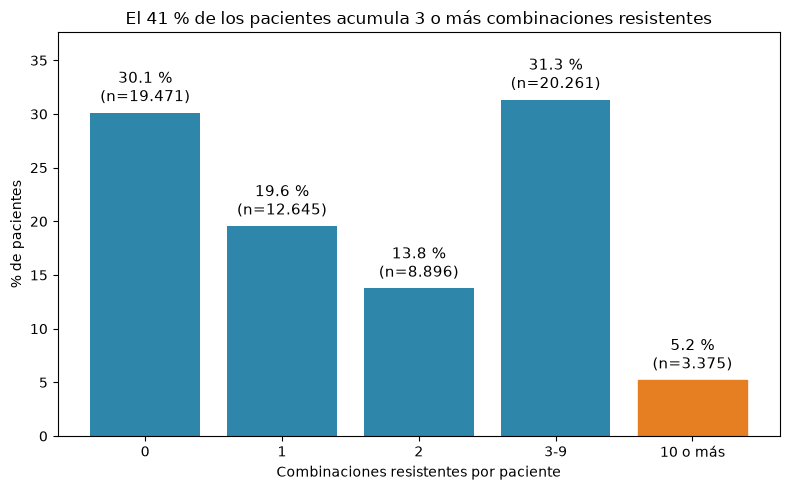

In [28]:
print("Representación gráfica de resistencias por paciente:")
conteo = pac["grupo_resistencias"].value_counts().sort_index()
pct = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(conteo.index.astype(str), pct, color="#2E86AB")
barras[-1].set_color("#E67E22")      # destaca el grupo con más carga (≥10)

for b, n, p in zip(barras, conteo, pct):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.6,
            f"{p:.1f} %\n(n={n:,})".replace(",", "."),
            ha="center", va="bottom", fontsize=11)

ax.set_ylim(0, pct.max() * 1.2)
ax.set_xlabel("Combinaciones resistentes por paciente")
ax.set_ylabel("% de pacientes")
ax.set_title("El 41 % de los pacientes acumula 3 o más combinaciones resistentes")
plt.tight_layout()
plt.show()

Se eligió el umbral de ≥3 combinaciones resistentes por situarse por encima de la mediana (2) y clasificar al 41 % de los pacientes; el gradiente por edad se mantuvo con los umbrales de ≥1, ≥2 y ≥10")

Con 64.648 pacientes, casi todo sale significativo. Valores por debajo de 0,01 de épsilon cuadrado son despreciables.
En las tablas resumen, la media del género 1 es 3,78 frente a 3,05, pero las dos medianas son 2. Mann-Whitney detecta diferencias en toda la distribución, no solo en la mediana, así que puede salir significativo aunque las medianas coincidan.
Kruskal dice que algún grupo difiere, pero no cuál. Para saberlo, usamos las medias y medianas que ya tenemos en las tablas.

In [29]:
from scipy.stats import false_discovery_control, kruskal, mannwhitneyu, spearmanr
 

# ===============================================================
#  TESTS ESTADÍSTICOS: ¿cambia el nº de combinaciones resistentes según el grupo?
#   Unidad de análisis: paciente (64.648).
#   Test elegido: no paramétrico, porque el recuento está muy sesgado (mediana 2, máximo 121)
#     - 2 grupos (gender)                    -> Mann-Whitney U
#     - 3 o más grupos (age, ADI)            -> Kruskal-Wallis
# ===============================================================
 
# Un paciente con más cultivos acumula más combinaciones: se comprueba y se repite el
# análisis con la tasa por cultivo
pac["tasa_por_cultivo"] = pac["n_combinaciones_resistentes"] / pac["n_cultivos"]
 
rho, p_rho = spearmanr(pac["n_cultivos"], pac["n_combinaciones_resistentes"])
print(f"Spearman entre n_cultivos y combinaciones resistentes: rho = {rho:.2f}")
 
resultados = []
 
for y in ["n_combinaciones_resistentes", "tasa_por_cultivo"]:
 
    # --- Dos grupos: gender -> Mann-Whitney U ---
    g0 = pac.loc[pac["gender"] == 0, y]
    g1 = pac.loc[pac["gender"] == 1, y]
    u, p = mannwhitneyu(g0, g1, alternative="two-sided")
    # Probabilidad de que un paciente del grupo 0 tenga un valor mayor que uno del grupo 1
    # (0,5 = sin diferencia)
    prob_superioridad = u / (len(g0) * len(g1))
    resultados.append({"resultado": y, "variable": "gender", "test": "Mann-Whitney U",
                       "estadístico": u, "p": p, "tamaño_efecto": prob_superioridad})
 
    # --- Tres o más grupos: age, ADI -> Kruskal-Wallis ---
    for v in ["age", "adi_score_cat", "adi_state_rank_cat"]:
        datos = pac[pac[v] != "Missing"]            # Missing no es un nivel del índice
        grupos = [g[y].values for _, g in datos.groupby(v, observed=True)]
        h, p = kruskal(*grupos)
        epsilon2 = h / (len(datos) - 1)             # épsilon cuadrado: tamaño del efecto (0-1)
        resultados.append({"resultado": y, "variable": v, "test": "Kruskal-Wallis",
                           "estadístico": h, "p": p, "tamaño_efecto": epsilon2})
 
tests = pd.DataFrame(resultados)
 
# Se hacen varios tests: p ajustado por comparaciones múltiples (Benjamini-Hochberg)
tests["p_ajustado"] = false_discovery_control(tests["p"])
tests["p"] = tests["p"].map(lambda x: "<0.001" if x < 0.001 else round(x, 3))
tests["p_ajustado"] = tests["p_ajustado"].map(lambda x: "<0.001" if x < 0.001 else round(x, 3))
tests["estadístico"] = tests["estadístico"].round(1)
tests["tamaño_efecto"] = tests["tamaño_efecto"].round(3)
 
print(tests.to_string(index=False))


Spearman entre n_cultivos y combinaciones resistentes: rho = 0.39
                  resultado           variable           test  estadístico      p  tamaño_efecto p_ajustado
n_combinaciones_resistentes             gender Mann-Whitney U  366016795.5 <0.001          0.453     <0.001
n_combinaciones_resistentes                age Kruskal-Wallis        750.7 <0.001          0.012     <0.001
n_combinaciones_resistentes      adi_score_cat Kruskal-Wallis        102.2 <0.001          0.002     <0.001
n_combinaciones_resistentes adi_state_rank_cat Kruskal-Wallis        134.9 <0.001          0.003     <0.001
           tasa_por_cultivo             gender Mann-Whitney U  359827838.0 <0.001          0.445     <0.001
           tasa_por_cultivo                age Kruskal-Wallis        554.1 <0.001          0.009     <0.001
           tasa_por_cultivo      adi_score_cat Kruskal-Wallis        272.2 <0.001          0.005     <0.001
           tasa_por_cultivo adi_state_rank_cat Kruskal-Wallis        3

Se compararon el número de combinaciones paciente-bacteria-antibiótico no sensibles entre grupos mediante tests no paramétricos (Mann-Whitney U y Kruskal-Wallis), dada la marcada asimetría de la distribución, y se repitió el análisis con la tasa por cultivo para controlar el número de cultivos por paciente (Spearman rho = 0,40). Todas las diferencias fueron estadísticamente significativas (p ajustado < 0,001), pero de pequeña magnitud: género (probabilidad de superioridad 0,456), edad (ε² = 0,013) y ADI (ε² ≤ 0,007). Las medianas fueron iguales en todos los grupos (2), de modo que las diferencias se concentran en los pacientes con mayor acumulación de resistencias.

<Axes: xlabel='res_ge_3_pct', ylabel='age'>

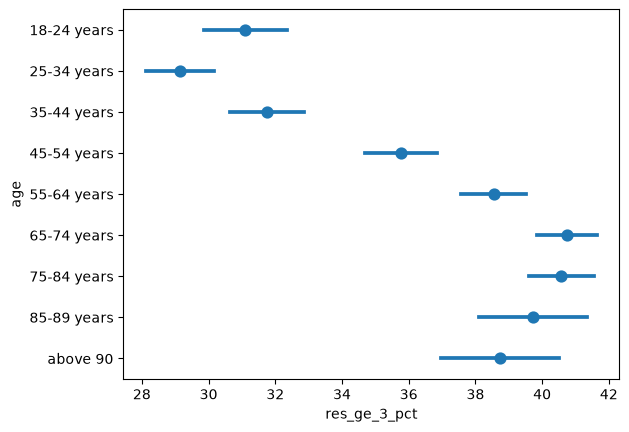

In [30]:
pac["res_ge_3_pct"] = pac["res_ge_3"] * 100
orden_edad = sorted(dfc["age"].dropna().unique())
sns.pointplot(data=pac, y="age", x="res_ge_3_pct", orient="h", errorbar=("se", 1.96), linestyle="none", order=orden_edad)

Los mayores tienen más cultivos, y más cultivos dan más oportunidades de acumular combinaciones, así que parte de este gradiente es mecánico.

Los mayores tienen más cultivos, y más cultivos dan más oportunidades de acumular combinaciones, así que parte de este gradiente es mecánico. Para comprobarlo, repetimos el gráfico solo con pacientes con un número similar de cultivos, por ejemplo pac[pac["n_cultivos"] == 1]. Si la pendiente se mantiene, es edad y no número de cultivos.

<Axes: xlabel='res_ge_3_pct', ylabel='age'>

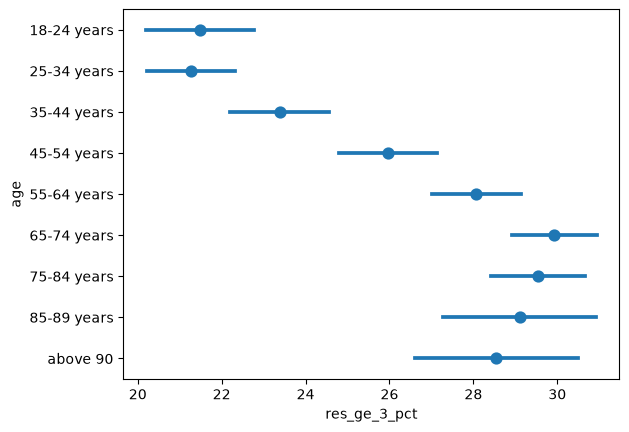

In [31]:
pac_1 = pac[pac["n_cultivos"] == 1]
sns.pointplot(data=pac_1, y="age", x="res_ge_3_pct", orient="h", errorbar=("se", 1.96), linestyle="none", order=orden_edad)

### 5.2 Factores sociodemográficos y clínicos

In [32]:

dfc["amr_bin"] = (dfc["amr"] == "Resistant").astype(int)
print("Cultivos:", len(dfc), "| prevalencia global de AMR:",
      round(dfc["amr_bin"].mean() * 100, 1), "%")
 
# Variables derivadas para el análisis
dfc["n_organismos_cat"] = dfc["n_organismos"].clip(upper=3).map({1: "1", 2: "2", 3: "3+"})
dfc["n_antibioticos_cat"] = pd.qcut(dfc["n_antibioticos"], 4, duplicates="drop").astype(str)

 


Cultivos: 113991 | prevalencia global de AMR: 67.6 %



VARIABLE: age
             AMR_0_n  AMR_0_%  AMR_1_n  AMR_1_%
age                                            
18-24 years     3193     8.63     5234     6.80
25-34 years     4485    12.12     8305    10.79
35-44 years     3954    10.69     7100     9.22
45-54 years     4249    11.49     8412    10.92
55-64 years     5139    13.89    11537    14.98
65-74 years     6174    16.69    14005    18.19
75-84 years     5699    15.41    13106    17.02
85-89 years     2193     5.93     4927     6.40
above 90        1904     5.15     4375     5.68

VARIABLE: gender
        AMR_0_n  AMR_0_%  AMR_1_n  AMR_1_%
gender                                    
0.0       29263    79.11    54862    71.25
1.0        7727    20.89    22139    28.75

VARIABLE: adi_score_cat
                           AMR_0_n  AMR_0_%  AMR_1_n  AMR_1_%
adi_score_cat                                                
Least Deprived (Q1)          10994    29.72    20513    26.64
Low Deprivation (Q2)          4174    11.28     8452    

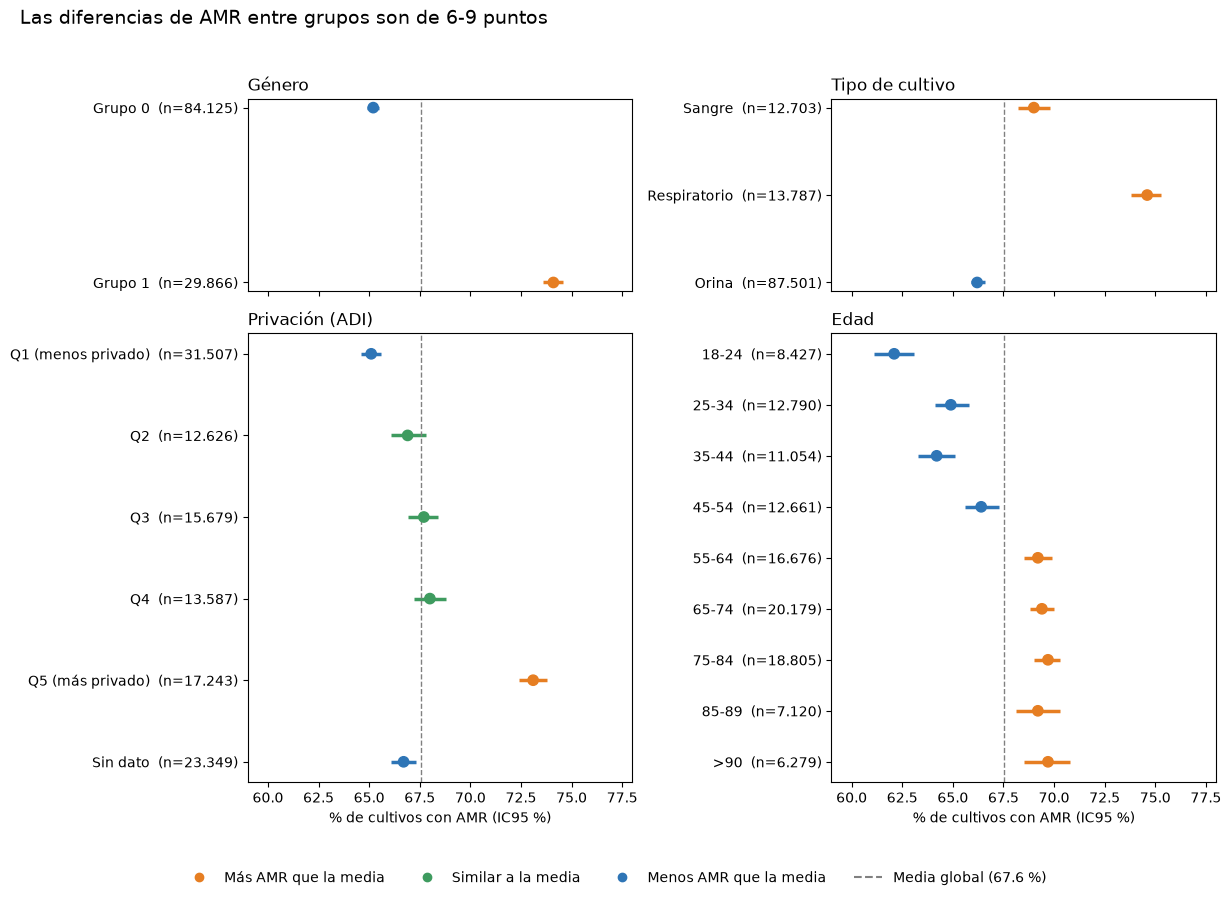

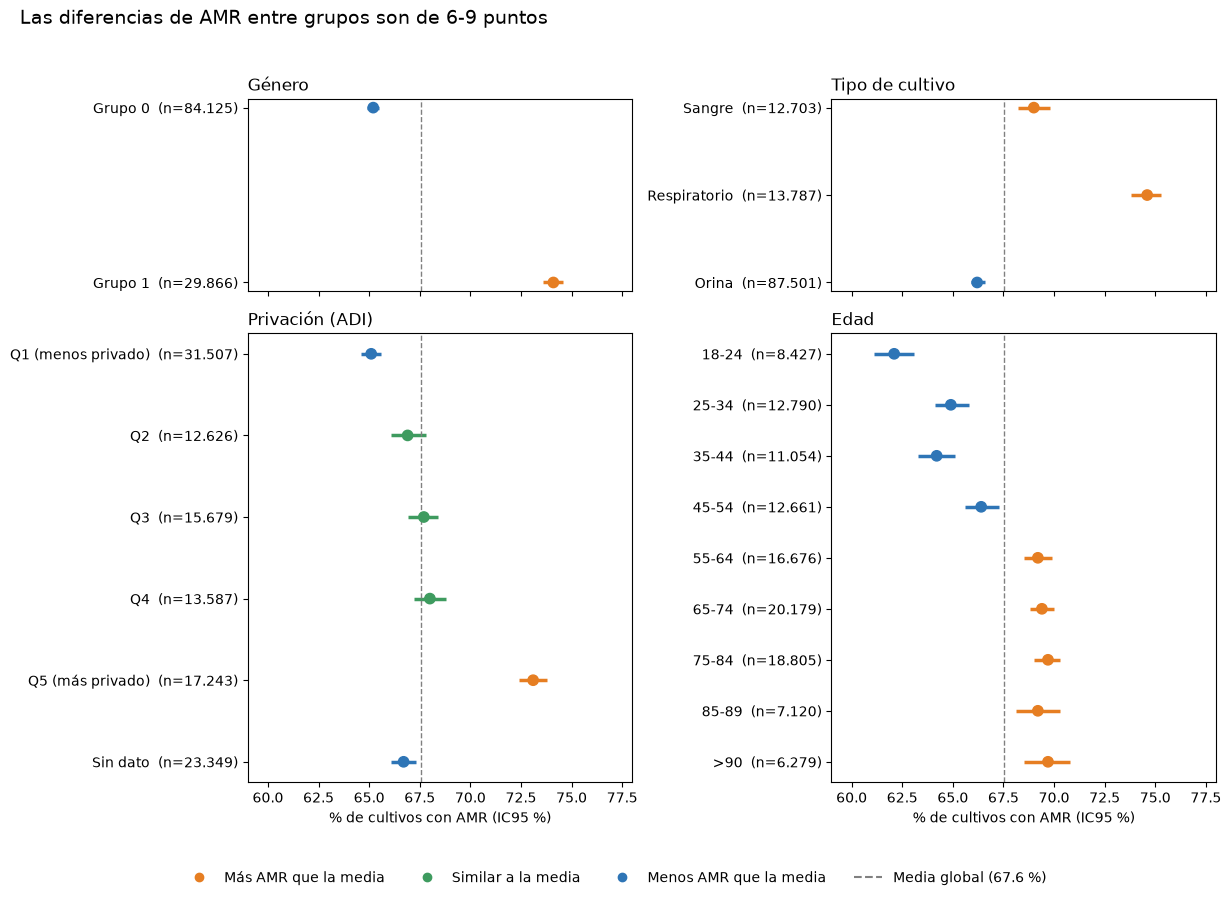

In [33]:

# ===============================================================
# COMPARACIÓN DE CARACTERÍSTICAS ENTRE CULTIVOS AMR=0 Y AMR=1
# ===============================================================
from utils.amr_def import panel_amr
set_data(dfc)
variables_comparacion = [
    "age",
    "gender",
    "adi_score_cat",
    "adi_state_rank_cat",
    "culture_description",
    "ordering_mode",
    "IP",
    "OP",
    "ICU",
    "ER"
]

for v in variables_comparacion:

    print(f"\n{'='*65}")
    print(f"VARIABLE: {v}")
    print("="*65)

    # Tabla de frecuencias absolutas
    tabla_n = pd.crosstab(
        dfc[v],
        dfc["amr_bin"]
    )

    # Porcentaje dentro de cada grupo AMR
    tabla_pct = pd.crosstab(
        dfc[v],
        dfc["amr_bin"],
        normalize="columns"
    ) * 100

    # Unimos frecuencias y porcentajes
    resultado = pd.DataFrame({
        "AMR_0_n": tabla_n.get(0, 0),
        "AMR_0_%": tabla_pct.get(0, 0).round(2),
        "AMR_1_n": tabla_n.get(1, 0),
        "AMR_1_%": tabla_pct.get(1, 0).round(2)
    })

    print(resultado)

panel_amr(["gender", "culture_description", "adi_score_cat", "age"],
          titulo="Las diferencias de AMR entre grupos son de 6-9 puntos")


In [34]:
# 1. Tabla de % de AMR por categoría

set_data(dfc)
for v in variables_comparacion:
    print(f"\n=== {v} ===")
    print(amr_por(v))


=== age ===
                 n      k  pct_amr  ic_low  ic_high
age                                                
18-24 years   8427   5234     62.1    61.1     63.1
25-34 years  12790   8305     64.9    64.1     65.8
35-44 years  11054   7100     64.2    63.3     65.1
45-54 years  12661   8412     66.4    65.6     67.3
55-64 years  16676  11537     69.2    68.5     69.9
65-74 years  20179  14005     69.4    68.8     70.0
75-84 years  18805  13106     69.7    69.0     70.3
85-89 years   7120   4927     69.2    68.1     70.3
above 90      6279   4375     69.7    68.5     70.8

=== gender ===
            n      k  pct_amr  ic_low  ic_high
gender                                        
0.0     84125  54862     65.2    64.9     65.5
1.0     29866  22139     74.1    73.6     74.6

=== adi_score_cat ===
                               n      k  pct_amr  ic_low  ic_high
adi_score_cat                                                    
Least Deprived (Q1)        31507  20513     65.1    64.6

In [35]:
# 2. Ranking de asociación con AMR (V de Cramér = tamaño del efecto)
ranking = pd.DataFrame([asociacion(v) for v in variables_comparacion]).sort_values(
    "cramers_v", ascending=False
)
print("\nRanking de asociación con AMR:")
print(ranking.to_string(index=False))


Ranking de asociación con AMR:
           variable  chi2             p  cramers_v
             gender 798.4 1.213631e-175      0.084
culture_description 389.3  2.891199e-85      0.058
      adi_score_cat 339.6  3.095010e-71      0.055
                age 329.6  2.055151e-66      0.054
 adi_state_rank_cat 333.9  5.105290e-70      0.054
      ordering_mode 127.2  1.661580e-29      0.033
                 IP 127.2  1.661580e-29      0.033
                 OP 127.2  1.661580e-29      0.033
                ICU  80.6  2.790498e-19      0.027
                 ER   0.0  9.810940e-01      0.000



CORRELACIÓN DE VARIABLES EPIDEMIOLÓGICAS CON AMR
                  spearman  pearson
gender               0.084    0.084
adi_score_q          0.056    0.056
adi_state_rank_q     0.054    0.059
age_ord              0.048    0.049
IP                   0.033    0.033
OP                  -0.033   -0.033
ICU                  0.027    0.027
ER                  -0.000   -0.000


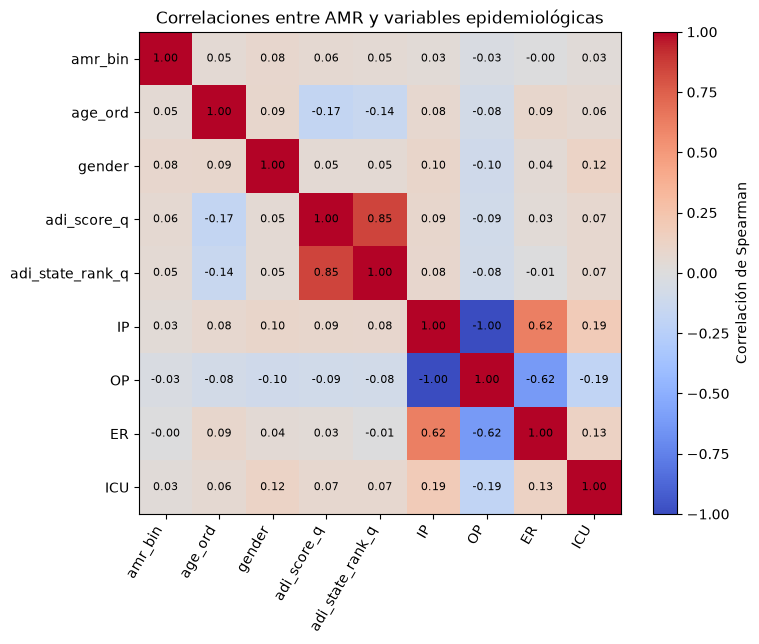

In [36]:

# ---------------------------------------------------------------
# A5. Correlaciones (Spearman y Pearson)
#     Se excluyen las variables relacionadas con el testeo
#     microbiológico: n_antibioticos, n_organismos y n_resistentes.
# ---------------------------------------------------------------

# Edad como variable ordinal (1-9)
orden_edad = sorted(dfc["age"].dropna().unique())

dfc["age_ord"] = dfc["age"].map({
    a: i + 1 for i, a in enumerate(orden_edad)
})

# Variables socioeconómicas como ordinales
dfc["adi_score_q"] = a_codigo(dfc["adi_score_cat"])
dfc["adi_state_rank_q"] = a_codigo(dfc["adi_state_rank_cat"])

# Variables demográficas, socioeconómicas y hospitalarias
vars_corr = [
    "age_ord",
    "gender",
    "adi_score_q",
    "adi_state_rank_q",
    "IP",
    "OP",
    "ER",
    "ICU"
]

# Correlaciones con AMR
corr_amr = pd.DataFrame({
    "spearman": dfc[vars_corr].corrwith(
        dfc["amr_bin"], method="spearman"
    ),
    "pearson": dfc[vars_corr].corrwith(
        dfc["amr_bin"], method="pearson"
    )
}).round(3)

# Ordenar según la magnitud de Spearman
corr_amr = corr_amr.reindex(
    corr_amr["spearman"].abs().sort_values(
        ascending=False
    ).index
)

print("\nCORRELACIÓN DE VARIABLES EPIDEMIOLÓGICAS CON AMR")
print(corr_amr)


# ---------------------------------------------------------------
# Mapa de calor de correlaciones (Spearman)
# ---------------------------------------------------------------

m = dfc[["amr_bin"] + vars_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))

im = ax.imshow(
    m.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(m)))
ax.set_xticklabels(m.columns, rotation=60, ha="right")

ax.set_yticks(range(len(m)))
ax.set_yticklabels(m.index)

for i in range(len(m)):
    for j in range(len(m)):
        ax.text(
            j, i,
            f"{m.values[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, label="Correlación de Spearman")

ax.set_title(
    "Correlaciones entre AMR y variables epidemiológicas"
)

plt.tight_layout()
plt.show()



Podemos ver que en este caso el HeatMap no es muy representativo porque los coeficientes de relación son muy debiles entre nuestra variables de estudio, exceptuando aquellas que están directamente relacionadas, como ocurre con las hospitalarias (``ward.csv``) y las de ``adi.csv``


TABLA RESUMEN: asociación de cada variable con AMR
           variable         bloque    tipo                    AMR más baja [IC95%]                   AMR más alta [IC95%]  dif_pp  cramers_v  spearman p_chi2  magnitud
             gender    demográfico binaria                 0.0: 65.2 % [64.9-65.5]                1.0: 74.1 % [73.6-74.6]     8.9      0.084     0.084 <0.001 muy débil
culture_description        clínico nominal               URINE: 66.2 % [65.9-66.6]        RESPIRATORY: 74.6 % [73.8-75.3]     8.4      0.058       NaN <0.001 muy débil
      adi_score_cat socioeconómico ordinal Least Deprived (Q1): 65.1 % [64.6-65.6] Most Deprived (Q5): 73.1 % [72.4-73.8]     8.0      0.055     0.056 <0.001 muy débil
                age    demográfico ordinal         18-24 years: 62.1 % [61.1-63.1]        75-84 years: 69.7 % [69.0-70.3]     7.6      0.054     0.048 <0.001 muy débil
 adi_state_rank_cat socioeconómico ordinal Least Deprived (Q1): 66.2 % [65.8-66.6] Most Deprived (Q5): 75.0 

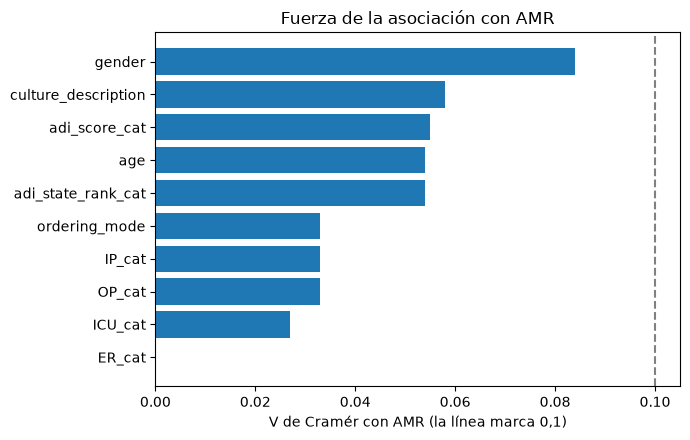

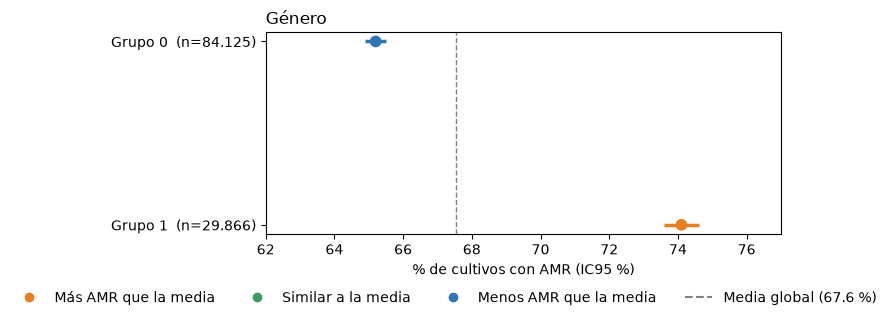

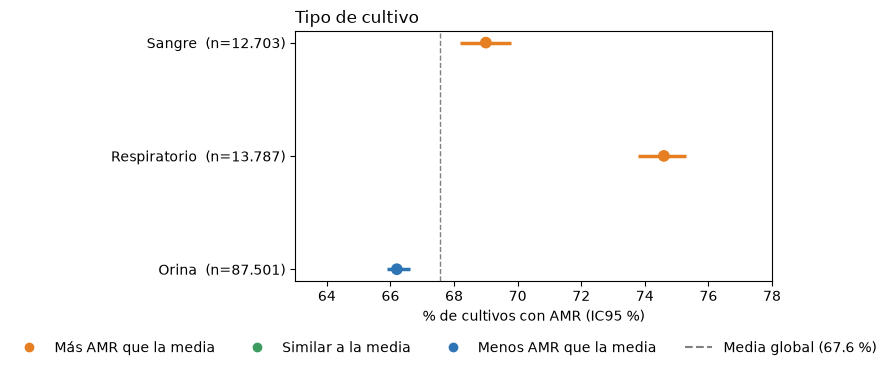

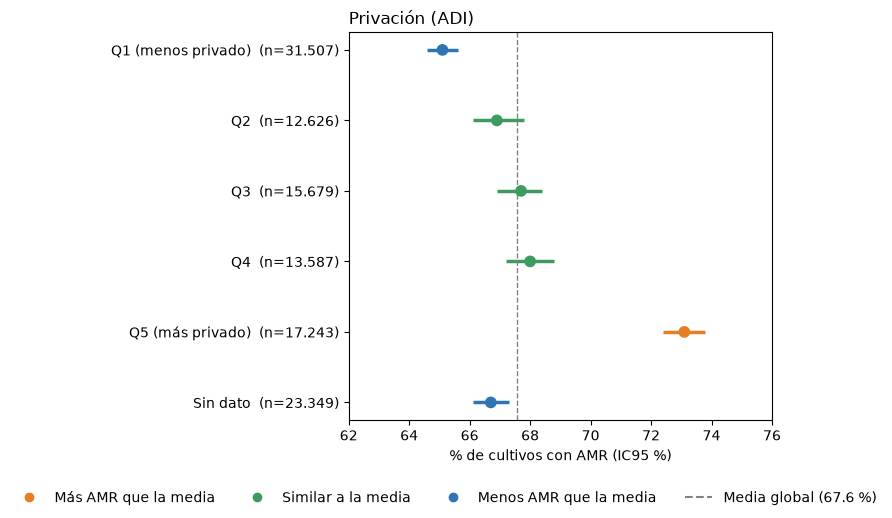

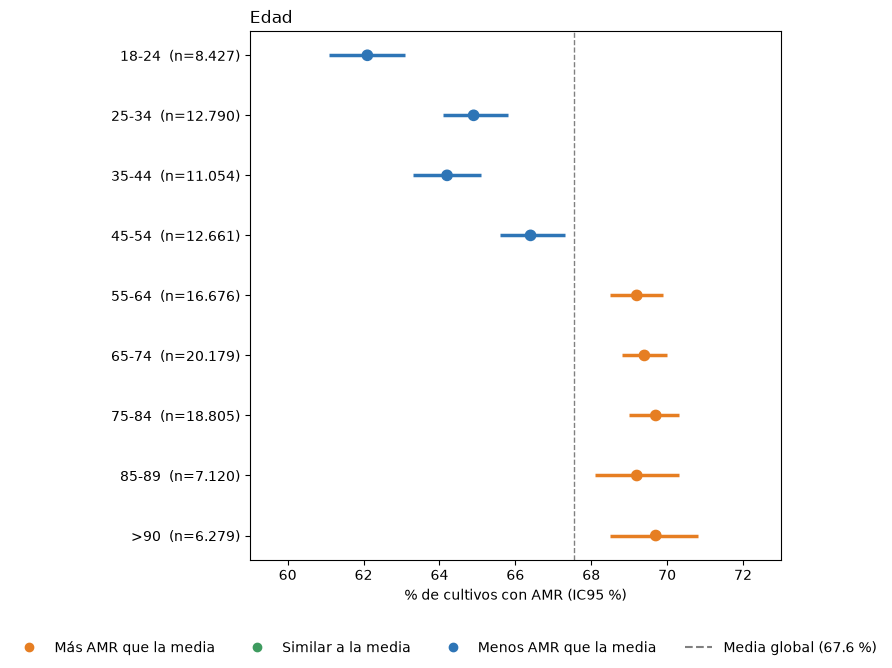

In [37]:

# ---------------------------------------------------------------
# A6. TABLA RESUMEN COMBINADA (una fila por variable)
# ---------------------------------------------------------------

dfc["ordering_bin"] = (dfc["ordering_mode"] == "Outpatient").astype(int)

for c in ["IP", "OP", "ER", "ICU"]:
    dfc[c + "_cat"] = dfc[c].map({0: "No", 1: "Sí"})

set_data(dfc)    # vuelve a enlazar los datos con utils.amr_def

# Versiones numéricas para calcular Spearman con AMR
version_num = {
    "age": "age_ord",
    "gender": "gender",
    "ordering_mode": "ordering_bin",
    "IP_cat": "IP",
    "OP_cat": "OP",
    "ER_cat": "ER",
    "ICU_cat": "ICU",
    "adi_score_cat": "adi_score_q",
    "adi_state_rank_cat": "adi_state_rank_q",
}

# Variables nominales: solo V de Cramér
nominales = ["culture_description"]

# Bloque de cada variable
bloque = {
    "age": "demográfico",
    "gender": "demográfico",
    "ordering_mode": "hospitalario",
    "IP_cat": "hospitalario",
    "OP_cat": "hospitalario",
    "ER_cat": "hospitalario",
    "ICU_cat": "hospitalario",
    "adi_score_cat": "socioeconómico",
    "adi_state_rank_cat": "socioeconómico",
    "culture_description": "clínico",
}


def fmt(g, cat):
    return (
        f"{cat}: {g.loc[cat, 'pct_amr']} % "
        f"[{g.loc[cat, 'ic_low']}-{g.loc[cat, 'ic_high']}]"
    )


# Variables incluidas en el análisis
variables_analisis = [
    "age",
    "gender",
    "ordering_mode",
    "IP_cat",
    "OP_cat",
    "ER_cat",
    "ICU_cat",
    "adi_score_cat",
    "adi_state_rank_cat",
    "culture_description",
]


filas = []

for v in variables_analisis:

    g = amr_por(v)
    g = g[g["n"] >= 100]

    cmin = g["pct_amr"].idxmin()
    cmax = g["pct_amr"].idxmax()

    a = asociacion(v)

    num = version_num.get(v)
    n_cat = dfc[v].nunique()

    filas.append({
        "variable": v,
        "bloque": bloque[v],
        "tipo": "nominal" if v in nominales else (
            "binaria" if n_cat == 2 else "ordinal"
        ),
        "AMR más baja [IC95%]": fmt(g, cmin),
        "AMR más alta [IC95%]": fmt(g, cmax),
        "dif_pp": round(
            g["pct_amr"].max() - g["pct_amr"].min(), 1
        ),
        "cramers_v": a["cramers_v"],
        "spearman": (
            round(
                dfc[num].corr(dfc["amr_bin"], method="spearman"), 3
            ) if num else np.nan
        ),
        "p_chi2": (
            "<0.001" if a["p"] < 0.001 else round(a["p"], 3)
        ),
    })


# Tabla resumen
resumen = pd.DataFrame(filas).sort_values(
    "cramers_v", ascending=False
)

resumen["magnitud"] = pd.cut(
    resumen["cramers_v"],
    [-1, 0.1, 0.3, 0.5, 1],
    labels=["muy débil", "débil", "moderada", "fuerte"]
)

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60)

print("\nTABLA RESUMEN: asociación de cada variable con AMR")
print(resumen.to_string(index=False))


# ---------------------------------------------------------------
# GRÁFICO: V DE CRAMÉR DE TODAS LAS VARIABLES
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

r = resumen.iloc[::-1]

ax.barh(r["variable"], r["cramers_v"])
ax.axvline(0.1, ls="--", color="gray")

ax.set_xlabel("V de Cramér con AMR (la línea marca 0,1)")
ax.set_title("Fuerza de la asociación con AMR")

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------
# GRÁFICOS DE PREVALENCIA DE AMR CON IC95%
# Para las 4 variables con mayor V de Cramér
# ---------------------------------------------------------------

for v in resumen["variable"].head(4):
    plot_amr(v)

En estos gráficos de prevalencia apenas se observa la diferencia del porcentaje de resistencia entre categorías. Modificaremos nuestros ejes para que sea más representativo. 

Limitaciones: multivariabilidad, no independencia y causalidad. La resistencia antimicrobiana es un fenómeno multifactorial, y este análisis solo recoge una parte de sus determinantes: no se han incluido la resistencia previa ni las comorbilidades, que probablemente influyen en el riesgo y pueden confundir las asociaciones observadas. Además, los tests de chi-cuadrado asumen observaciones independientes, y aquí los 113.991 cultivos proceden de unos 64.600 pacientes, por lo que los p-valores son más optimistas de lo debido; la regresión logística con errores estándar agrupados por paciente corrige este problema. Por último, al tratarse de datos observacionales existe confusión probable (por ejemplo, el tipo de muestra puede mezclarse con el género, el ámbito con la gravedad del paciente, y la ausencia de ADI no es aleatoria). El ajuste multivariante reduce esa confusión, pero no la elimina, de modo que los resultados deben interpretarse como asociaciones y no como relaciones causales: los factores “se asocian con” la AMR, no la “causan” ni la “provocan”.

### 5.3 Análisis del perfil microbiológico de las resistencias.
Bacterias resistentes y a qué antibióticos


Filas S/I/R: 1535637 | cultivos: 113991
Antibióticos repetidos en un mismo cultivo y organismo: 7608

Organismos (≥100 cultivos) ordenados por % de AMR:
                                                              n_cultivos      k  pct_amr  ic_low  ic_high
organism                                                                                                 
MORGANELLA MORGANII                                                  653    653    100.0    99.4    100.0
STAPH AUREUS {MRSA}                                                 1303   1303    100.0    99.7    100.0
PROVIDENCIA RETTGERI                                                 109    109    100.0    96.6    100.0
PROTEUS VULGARIS GROUP                                               134    134    100.0    97.2    100.0
SERRATIA MARCESCENS                                                  819    818     99.9    99.3    100.0
ZZZENTEROBACTER AEROGENES                                            662    661     99.8    99.1    100.

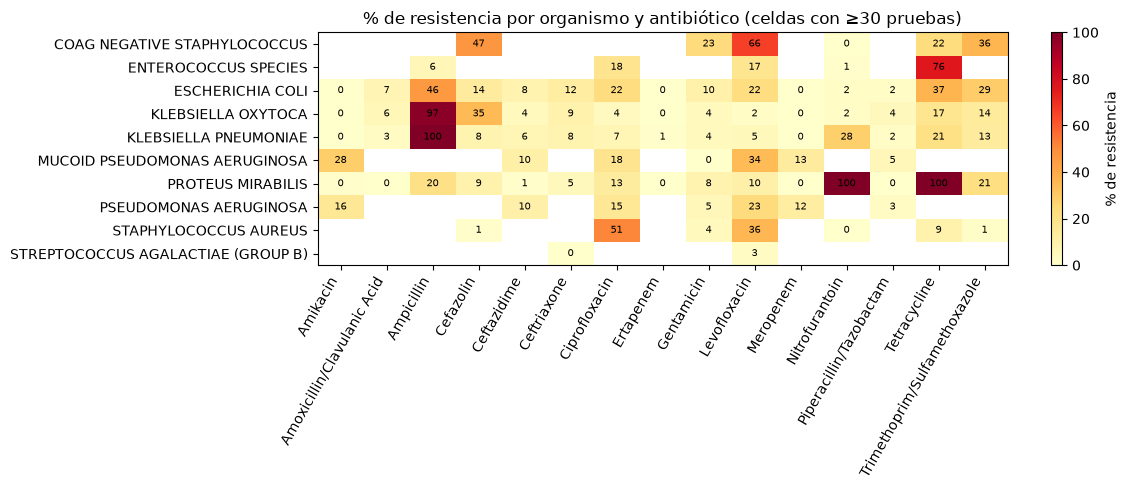

In [ ]:

# ===============================================================
# POR CULTIVO Bacterias resistentes y a qué antibióticos
# ===============================================================
# Susceptible, Intermediate y Resistant (igual que la cohorte del notebook):
# Intermediate cuenta como NO resistente
res = res[res["susceptibility"].isin(["Susceptible", "Intermediate", "Resistant"])].copy()
res["resistente"] = (res["susceptibility"] == "Resistant").astype(int)
 
print("\nFilas S/I/R:", len(res), "| cultivos:", res["culture_id"].nunique())
print("Antibióticos repetidos en un mismo cultivo y organismo:",
      res.duplicated(["culture_id", "organism", "antibiotic"]).sum())
 
# B1. Ranking de organismos: % de cultivos-organismo con al menos una R
org = res.groupby(["culture_id", "organism"])["resistente"].max().reset_index()
rank_org = org.groupby("organism")["resistente"].agg(n_cultivos="size", k="sum")
rank_org = rank_org[rank_org["n_cultivos"] >= 100].copy()
rank_org["pct_amr"] = rank_org["k"] / rank_org["n_cultivos"] * 100
lo, hi = wilson(rank_org["k"], rank_org["n_cultivos"])
rank_org["ic_low"], rank_org["ic_high"] = lo * 100, hi * 100
rank_org = rank_org.sort_values("pct_amr", ascending=False).round(1)
print("\nOrganismos (≥100 cultivos) ordenados por % de AMR:")
print(rank_org)
 
# B2. Antibióticos con mayor % de resistencia (≥100 pruebas)
rank_abx = res.groupby("antibiotic")["resistente"].agg(n_pruebas="size", k="sum")
rank_abx = rank_abx[rank_abx["n_pruebas"] >= 100].copy()
rank_abx["pct_resistente"] = (rank_abx["k"] / rank_abx["n_pruebas"] * 100).round(1)
print("\nAntibióticos (≥100 pruebas) ordenados por % de resistencia:")
print(rank_abx.sort_values("pct_resistente", ascending=False))
 
# B3. Heatmap organismo x antibiótico (% de resistencia)
top_org = org["organism"].value_counts().head(10).index
top_abx = res["antibiotic"].value_counts().head(15).index
sub = res[res["organism"].isin(top_org) & res["antibiotic"].isin(top_abx)]
pct = sub.pivot_table(index="organism", columns="antibiotic",
                      values="resistente", aggfunc="mean") * 100
n_pruebas = sub.pivot_table(index="organism", columns="antibiotic",
                            values="resistente", aggfunc="size")
pct = pct.where(n_pruebas >= 30)  # ocultar celdas con menos de 30 pruebas
 
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pct.values, cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(pct.shape[1]), pct.columns, rotation=60, ha="right")
ax.set_yticks(range(pct.shape[0]), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        if not np.isnan(pct.values[i, j]):
            ax.text(j, i, f"{pct.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="% de resistencia")
ax.set_title("% de resistencia por organismo y antibiótico (celdas con ≥30 pruebas)")
plt.tight_layout()
plt.show()
 


Cultivos: 113991 | Pacientes: 64648
Cultivo x organismo: 127729 | Paciente x organismo: 87752
                                                                   n          pct_resistente         
unidad                                                       Cultivo Paciente        Cultivo Paciente
organism                                                                                             
ACHROMOBACTER XYLOSOXIDANS                                       459      174           99.8    100.0
ENTEROBACTER CLOACAE                                             380      346           99.7    100.0
STAPH AUREUS {MRSA}                                             1303      724          100.0    100.0
PROTEUS VULGARIS GROUP                                           134      119          100.0    100.0
MORGANELLA MORGANII                                              653      560          100.0    100.0
SERRATIA MARCESCENS                                              819      672           99

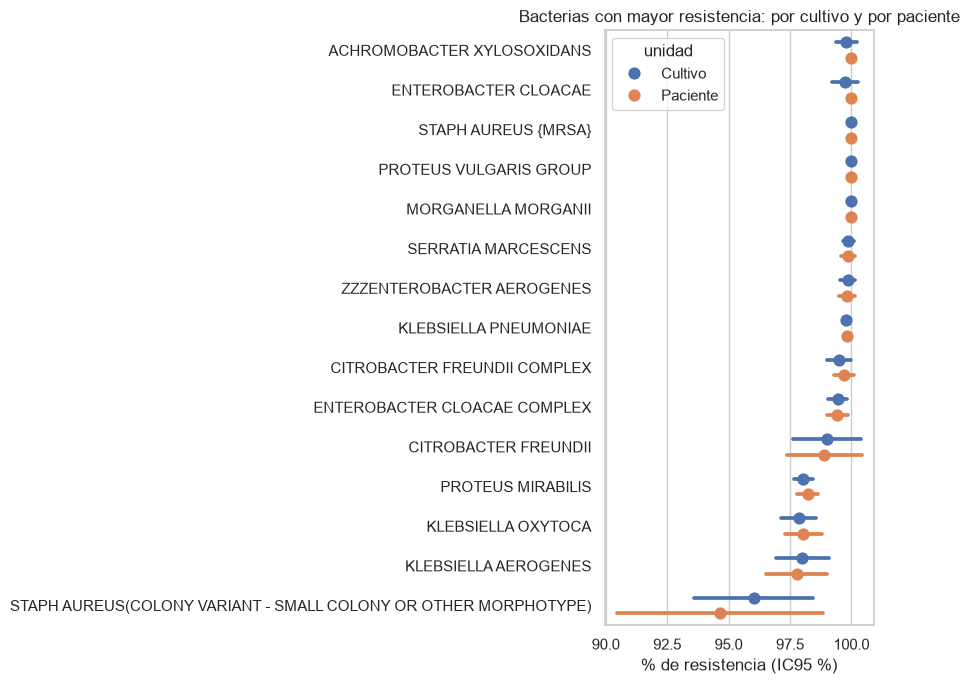

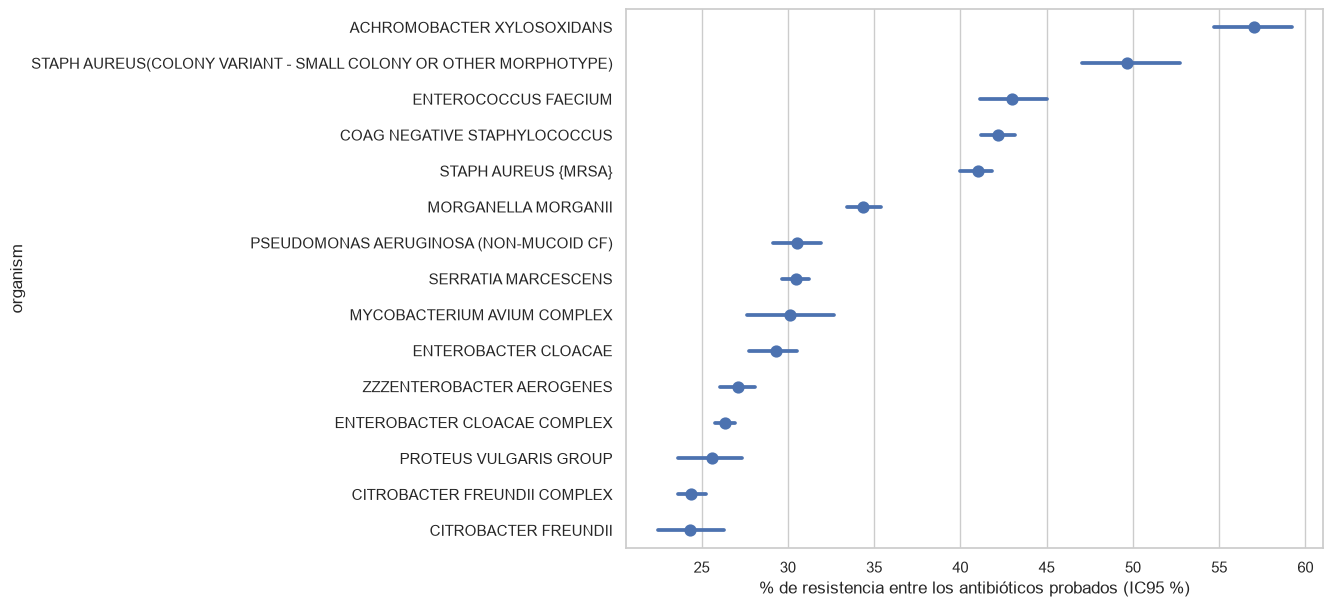

                           n_pruebas  pct_resistente
antibiotic                                          
Ampicillin                     63023            50.2
Quinupristin/Dalfopristin        263            48.7
Erythromycin                   11617            46.2
Tetracycline                   44822            43.8
Minocycline                      268            38.1
Piperacillin                    1015            36.0
Moxifloxacin                    6801            35.8
Penicillin                     16489            35.3
Cefuroxime                      5002            34.8
Clindamycin                    11983            34.2
Ticarcillin                      695            34.0
Oxacillin                       6610            33.4
Ampicillin/Sulbactam           16642            32.5
Doxycycline                     1352            31.0
Doripenem                        672            23.5


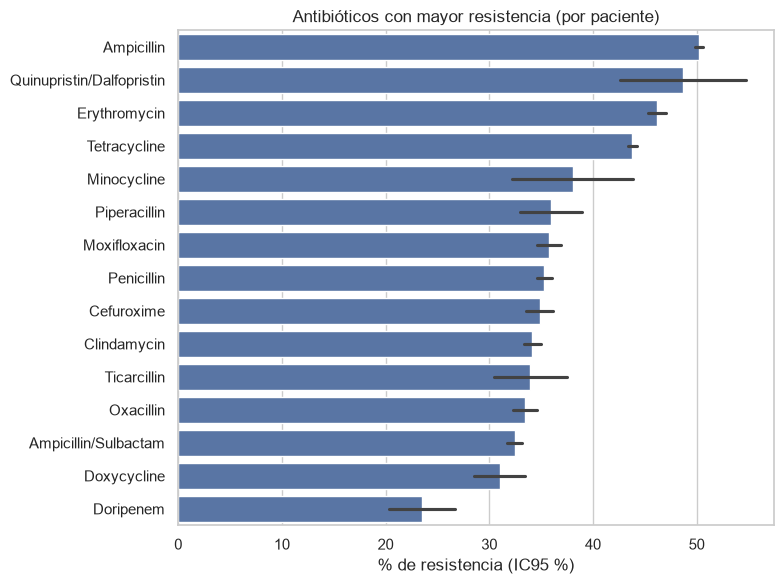

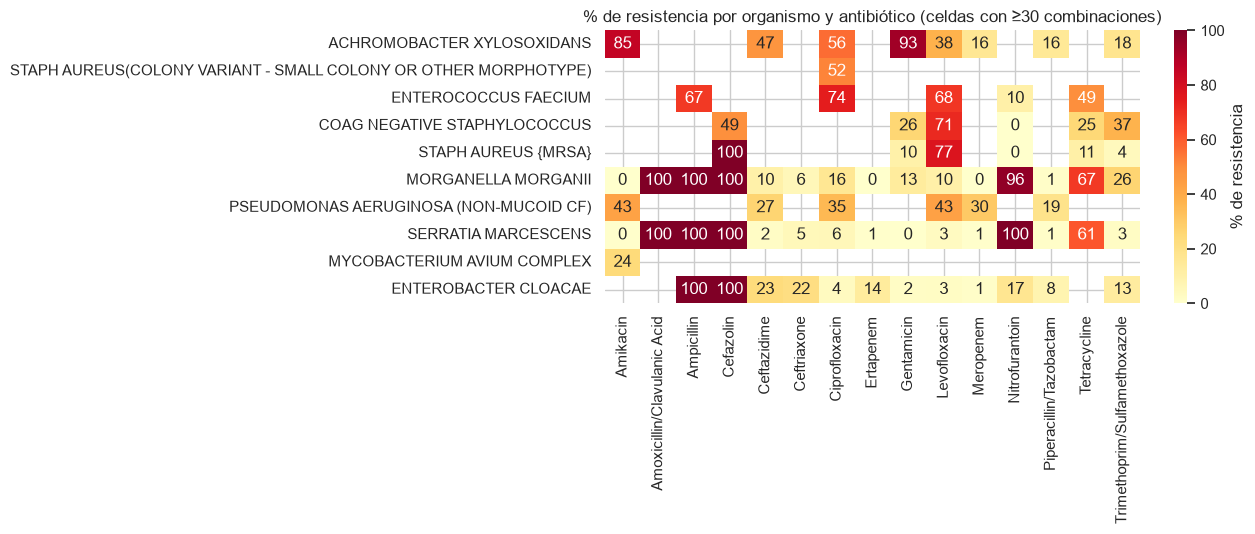

In [39]:

sns.set_theme(style="whitegrid")

#ANALISIS POR PACIENTE
 
RESISTENTES = ["Resistant"]
 
r = res[res["susceptibility"].isin(["Susceptible", "Intermediate", "Resistant"])].copy()
r["resistente_pct"] = r["susceptibility"].isin(RESISTENTES) * 100   # 0 o 100: la media = % de resistencia
 
# Unidad 1: cultivo x organismo (resistente si algún antibiótico lo es)
org_cultivo = r.groupby(["culture_id", "organism"], as_index=False)["resistente_pct"].max()
 
# Unidad 2: paciente x organismo (resistente si lo fue en algún cultivo).
# Evita contar varias veces a un paciente con muchos cultivos.
org_paciente = r.groupby(["anon_id", "organism"], as_index=False)["resistente_pct"].max()
 
print("Cultivos:", r["culture_id"].nunique(), "| Pacientes:", r["anon_id"].nunique())
print("Cultivo x organismo:", len(org_cultivo), "| Paciente x organismo:", len(org_paciente))
 
# ===============================================================
# 5.3.2 RANKING DE BACTERIAS: UNIDAD CULTIVO FRENTE A UNIDAD PACIENTE
# ===============================================================
# Organismos con al menos 100 pacientes, ordenados por % de resistencia (top 15). Va a salir todo en 100 y no nos interesa
n_pac = org_paciente["organism"].value_counts()
frecuentes = n_pac[n_pac >= 100].index
orden = (org_paciente[org_paciente["organism"].isin(frecuentes)]
         .groupby("organism")["resistente_pct"].mean()
         .sort_values(ascending=False).index[:15])
 
comp = pd.concat([org_cultivo.assign(unidad="Cultivo"),
                  org_paciente.assign(unidad="Paciente")])
comp = comp[comp["organism"].isin(orden)]
 
print(comp.groupby(["organism", "unidad"])["resistente_pct"]
      .agg(n="size", pct_resistente="mean").round(1).unstack("unidad").loc[orden])
 
plt.figure(figsize=(9, 7))
sns.pointplot(data=comp, y="organism", x="resistente_pct", hue="unidad", order=orden,
              orient="h", dodge=0.4, linestyle="none", errorbar=("se", 1.96))
plt.xlabel("% de resistencia (IC95 %)")
plt.ylabel("")
plt.title("Bacterias con mayor resistencia: por cultivo y por paciente")
plt.tight_layout()
plt.show()


#Usa como resultado el % de resistencia entre los antibióticos probados en lugar de “alguna resistencia”. 
# Así cada organismo se mide con todos sus antibiogramas, y el efecto de la resistencia intrínseca se diluye en lugar de saturar. 
# Asi que vamos a cambiar esto: 

abx_paciente = r.groupby(["anon_id", "organism", "antibiotic"], as_index=False)["resistente_pct"].max()

n_org = abx_paciente.groupby("organism")["anon_id"].nunique()
frecuentes = n_org[n_org >= 100].index
sub = abx_paciente[abx_paciente["organism"].isin(frecuentes)]
orden = sub.groupby("organism")["resistente_pct"].mean().sort_values(ascending=False).index[:15]

plt.figure(figsize=(9, 7))
sns.pointplot(data=sub[sub["organism"].isin(orden)], y="organism", x="resistente_pct", order=orden,
              orient="h", linestyle="none", errorbar=("ci", 95), n_boot=200, color="C0")
plt.xlabel("% de resistencia entre los antibióticos probados (IC95 %)")
plt.show()
 
# ===============================================================
# 5.3.3 ANTIBIÓTICOS CON MAYOR RESISTENCIA (unidad: paciente x organismo x antibiótico)
# ===============================================================
abx_paciente = r.groupby(["anon_id", "organism", "antibiotic"], as_index=False)["resistente_pct"].max()
 
rank_abx = (abx_paciente.groupby("antibiotic")["resistente_pct"]
            .agg(n_pruebas="size", pct_resistente="mean"))
rank_abx = rank_abx[rank_abx["n_pruebas"] >= 100].sort_values("pct_resistente", ascending=False).round(1)
print(rank_abx.head(15))
 
top15_abx = rank_abx.head(15).index
plt.figure(figsize=(8, 6))
sns.barplot(data=abx_paciente[abx_paciente["antibiotic"].isin(top15_abx)],
            y="antibiotic", x="resistente_pct", order=top15_abx,
            errorbar=("se", 1.96), color="C0")
plt.xlabel("% de resistencia (IC95 %)")
plt.ylabel("")
plt.title("Antibióticos con mayor resistencia (por paciente)")
plt.tight_layout()
plt.show()
 
# ===============================================================
# 5.3.4 HEATMAP ORGANISMO x ANTIBIÓTICO (unidad: paciente)
#       Se ocultan las celdas con menos de 30 combinaciones
# ===============================================================
top_org = orden[:10]
top_abx = abx_paciente["antibiotic"].value_counts().head(15).index
sub = abx_paciente[abx_paciente["organism"].isin(top_org) & abx_paciente["antibiotic"].isin(top_abx)]
 
pct = sub.pivot_table(index="organism", columns="antibiotic", values="resistente_pct", aggfunc="mean").reindex(top_org)
n = sub.pivot_table(index="organism", columns="antibiotic", values="resistente_pct", aggfunc="size").reindex(top_org)
 
plt.figure(figsize=(13, 5.5))
sns.heatmap(pct.where(n >= 30), annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
            cbar_kws={"label": "% de resistencia"})
plt.xlabel("")
plt.ylabel("")
plt.title("% de resistencia por organismo y antibiótico (celdas con ≥30 combinaciones)")
plt.tight_layout()
plt.show()


Este ultimo heatmap elige los organismos del ranking de “más resistentes” (especies raras) y los antibióticos más frecuentes, y por eso sale casi vacío. E. coli, el organismo más frecuente, no aparece. Utilizaremos la version anterior

Antibióticos: los más probados y los de uso clínico habitual

El ranking anterior mezcla dos preguntas distintas, así que se separa en dos paneles:

- **A) Más de 1.000 pruebas.** Los 10 antibióticos con mayor % de resistencia entre los que tienen más de 1.000 combinaciones paciente-organismo probadas. Se excluyen los poco probados porque su estimación es muy imprecisa (por ejemplo, quinupristina/dalfopristina, n = 263). Este panel incluye resistencia intrínseca: la ampicilina, la tetraciclina o la eritromicina salen altas en parte porque muchas bacterias son resistentes de forma natural, no por AMR adquirida.
- **B) Uso clínico habitual.** Los antibióticos que se usan en la práctica diaria. Responde a la pregunta clínica: ¿con qué fármacos de uso común hay que tener cuidado?

Unidad: paciente × organismo × antibiótico. IC95 % de Wilson. La línea discontinua es la resistencia media de todas las pruebas.

A) Antibióticos con más de 1.000 pruebas (top 10 por % de resistencia)
                          n   pct    lo    hi
antibiotic                                   
Ampicillin            63023  50.2  49.9  50.6
Erythromycin          11617  46.2  45.3  47.1
Tetracycline          44822  43.8  43.4  44.3
Piperacillin           1015  36.0  33.1  39.0
Moxifloxacin           6801  35.8  34.6  36.9
Penicillin            16489  35.3  34.6  36.1
Cefuroxime             5002  34.8  33.5  36.2
Clindamycin           11983  34.2  33.3  35.0
Oxacillin              6610  33.4  32.3  34.6
Ampicillin/Sulbactam  16642  32.5  31.8  33.2


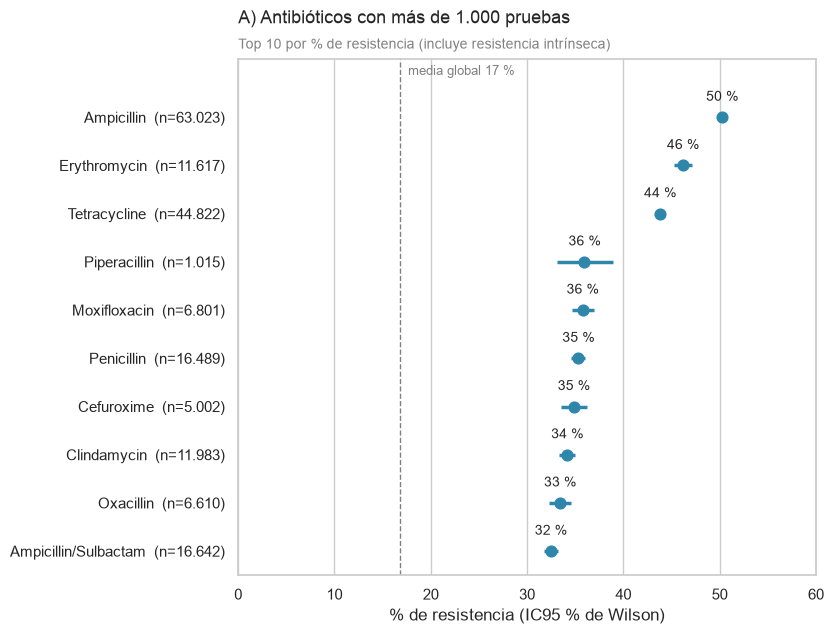


B) Antibióticos de uso clínico habitual
                                   n   pct    lo    hi
antibiotic                                            
Trimethoprim/Sulfamethoxazole  67263  23.4  23.1  23.7
Levofloxacin                   68801  17.3  17.0  17.6
Ciprofloxacin                  72607  17.2  17.0  17.5
Nitrofurantoin                 61181  12.6  12.3  12.9
Ceftriaxone                    49112  11.0  10.8  11.3
Gentamicin                     68064   8.5   8.3   8.7
Piperacillin/Tazobactam        57169   3.1   2.9   3.2
Meropenem                      46387   1.4   1.3   1.5
Ertapenem                      39454   0.5   0.4   0.6


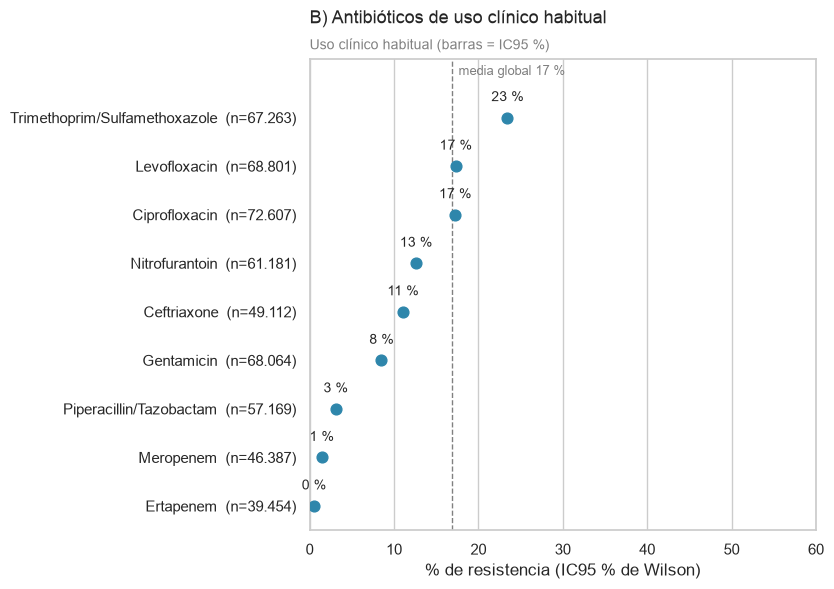

In [40]:
# ===============================================================
# 5.3.5 ANTIBIÓTICOS: (A) LOS MÁS PROBADOS Y (B) LOS DE USO CLÍNICO HABITUAL
#       Unidad: paciente x organismo x antibiótico (abx_paciente, ya calculado arriba)
#       IC95 % de Wilson. n = nº de combinaciones paciente-organismo probadas.
# ===============================================================



tabla_abx = (abx_paciente.groupby("antibiotic")["resistente_pct"]
             .agg(n="size", k=lambda x: (x == 100).sum()))
tabla_abx["pct"] = tabla_abx["k"] / tabla_abx["n"] * 100
lo, hi = wilson(tabla_abx["k"], tabla_abx["n"])
tabla_abx["lo"], tabla_abx["hi"] = lo * 100, hi * 100

pct_global = abx_paciente["resistente_pct"].mean()


def dibujar_abx(tabla, titulo, subtitulo, color):
    t = tabla.sort_values("pct", ascending=False)
    nombres = [f"{a}  (n={n:,})".replace(",", ".") for a, n in zip(t.index, t["n"])]
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(t) + 2))
    ax.hlines(y, t["lo"], t["hi"], color=color, lw=2.5)
    ax.scatter(t["pct"], y, color=color, s=60, zorder=3)
    for yi, p in zip(y, t["pct"]):
        ax.text(p, yi - 0.28, f"{p:.0f} %", ha="center", va="bottom", fontsize=10)
    ax.axvline(pct_global, ls="--", color="gray", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(nombres, fontsize=10.5)
    ax.set_ylim(len(t) - 0.5, -1.2)          # deja hueco arriba para la etiqueta de la media
    ax.set_xlim(0, max(60, np.ceil(t["hi"].max() / 10) * 10))
    ax.set_xlabel("% de resistencia (IC95 % de Wilson)")
    ax.set_title(titulo, fontsize=13, loc="left", pad=26)
    ax.text(0, 1.015, subtitulo, transform=ax.transAxes, fontsize=10, color="gray", va="bottom")
    ax.grid(axis="y", visible=False)
    ax.text(pct_global + 0.8, -0.95, f"media global {pct_global:.0f} %",
            fontsize=9, color="gray", va="center")
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------
# A) Antibióticos con MÁS DE 1.000 pruebas: los 10 con más resistencia
# ---------------------------------------------------------------
A = tabla_abx[tabla_abx["n"] > 1000].sort_values("pct", ascending=False).head(10)
print("A) Antibióticos con más de 1.000 pruebas (top 10 por % de resistencia)")
print(A[["n", "pct", "lo", "hi"]].round(1))
dibujar_abx(A, "A) Antibióticos con más de 1.000 pruebas",
            "Top 10 por % de resistencia (incluye resistencia intrínseca)",
            "#2E86AB")

# ---------------------------------------------------------------
# B) Antibióticos de uso clínico habitual (lista editable)
# ---------------------------------------------------------------
habituales = [
    "Ceftriaxone", "Ciprofloxacin", "Levofloxacin", "Trimethoprim/Sulfamethoxazole",
    "Nitrofurantoin", "Gentamicin", "Piperacillin/Tazobactam", "Meropenem", "Ertapenem",
]
faltan = [a for a in habituales if a not in tabla_abx.index]
if faltan:
    print("No aparecen en los datos (revisa el nombre):", faltan)

B = tabla_abx.loc[[a for a in habituales if a in tabla_abx.index]]
B = B[B["n"] >= 100]            # evita estimaciones con muy pocas pruebas
print("\nB) Antibióticos de uso clínico habitual")
print(B[["n", "pct", "lo", "hi"]].sort_values("pct", ascending=False).round(1))
dibujar_abx(B, "B) Antibióticos de uso clínico habitual",
            "Uso clínico habitual (barras = IC95 %)",
            "#2E86AB")

### EXTRA 5.4 Regresión multivariable logística

                           Logit Regression Results                           
Dep. Variable:                amr_bin   No. Observations:               113991
Model:                          Logit   Df Residuals:                   113971
Method:                           MLE   Df Model:                           19
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                 0.01231
Time:                        15:51:23   Log-Likelihood:                -70955.
converged:                       True   LL-Null:                       -71839.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                               

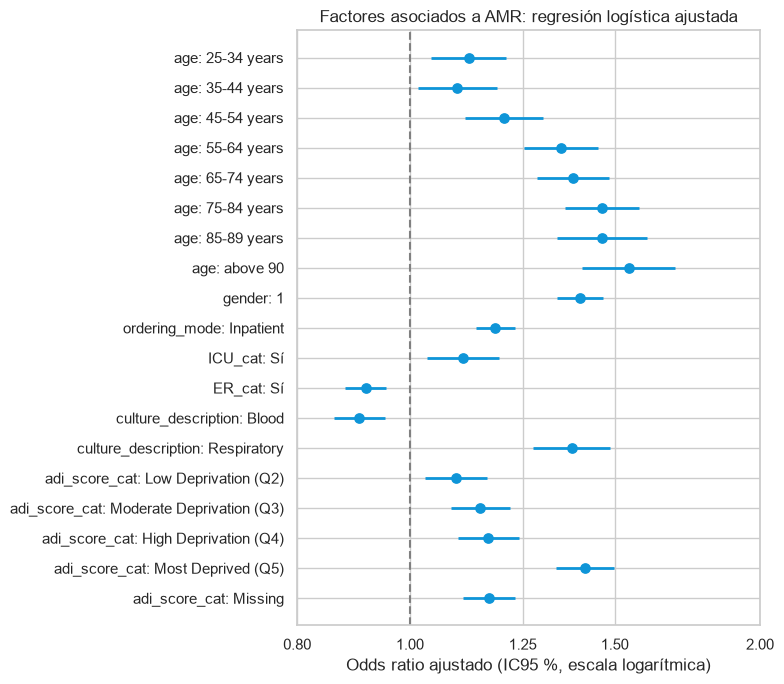

                                                              dy/dx  Std. Err.      z  Pr(>|z|)  Conf. Int. Low  Cont. Int. Hi.
C(age, Treatment("18-24 years"))[T.25-34 years]                2.51       0.82   3.05      0.00            0.90            4.13
C(age, Treatment("18-24 years"))[T.35-44 years]                2.02       0.86   2.35      0.02            0.34            3.71
C(age, Treatment("18-24 years"))[T.45-54 years]                4.02       0.85   4.75      0.00            2.36            5.68
C(age, Treatment("18-24 years"))[T.55-64 years]                6.46       0.81   7.96      0.00            4.87            8.05
C(age, Treatment("18-24 years"))[T.65-74 years]                6.97       0.79   8.80      0.00            5.42            8.52
C(age, Treatment("18-24 years"))[T.75-84 years]                8.22       0.81  10.20      0.00            6.64            9.80
C(age, Treatment("18-24 years"))[T.85-89 years]                8.20       0.98   8.38      0.00         

In [41]:

sns.set_theme(style="whitegrid")

# ===============================================================
# 1. DATOS DEL MODELO
#    Una fila por cultivo. Se usa ordering_mode como único indicador de ámbito
#    (IP y OP son la misma partición) y no se incluyen variables de testeo
#    (n_antibioticos, n_organismos), porque describen cuánto se probó y no
#    características del paciente.
# ===============================================================
cols = ["amr_bin", "anon_id", "age", "gender", "ordering_mode",
        "ICU_cat", "ER_cat", "culture_description", "adi_score_cat"]

dm = dfc[cols].dropna().copy()
dm["gender"] = dm["gender"].astype(int).astype(str)          # "0" / "1"
dm["adi_score_cat"] = dm["adi_score_cat"].astype(str)
dm["culture_description"] = dm["culture_description"].str.title()   # URINE -> Urine

grupos = pd.factorize(dm["anon_id"])[0]    # un paciente puede tener varios cultivos

# ===============================================================
# 2. REGRESIÓN LOGÍSTICA (categoría de referencia entre paréntesis)
#    Errores estándar robustos agrupados por paciente
# ===============================================================
formula = (
    'amr_bin ~ C(age, Treatment("18-24 years"))'
    ' + C(gender, Treatment("0"))'
    ' + C(ordering_mode, Treatment("Outpatient"))'
    ' + C(ICU_cat, Treatment("No"))'
    ' + C(ER_cat, Treatment("No"))'
    ' + C(culture_description, Treatment("Urine"))'
    ' + C(adi_score_cat, Treatment("Least Deprived (Q1)"))'
)

modelo = smf.logit(formula, data=dm).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": grupos}
)
print(modelo.summary())

# ===============================================================
# 3. ODDS RATIOS AJUSTADOS CON IC95%
# ===============================================================
ic = modelo.conf_int()
or_tabla = pd.DataFrame({
    "OR": np.exp(modelo.params),
    "IC_low": np.exp(ic[0]),
    "IC_high": np.exp(ic[1]),
    "p": modelo.pvalues,
}).drop(index="Intercept")

# Nombres legibles: 'C(age, Treatment("18-24 years"))[T.25-34 years]' -> 'age: 25-34 years'
or_tabla.index = or_tabla.index.str.replace(
    r'C\((\w+), Treatment\(.*?\)\)\[T\.(.*)\]', r'\1: \2', regex=True
)
print(or_tabla.round(3))

#ESTABLECEMOS EL ORDEN DE LAS VARIABLES EN NUESTRAS REPRESENTACIONES GRAFICAS
orden_adi = ["Low Deprivation (Q2)", "Moderate Deprivation (Q3)",
             "High Deprivation (Q4)", "Most Deprived (Q5)", "Missing"]

orden_filas = (
    [f"age: {a}" for a in ["25-34 years", "35-44 years", "45-54 years", "55-64 years",
                           "65-74 years", "75-84 years", "85-89 years", "above 90"]]
    + ["gender: 1", "ordering_mode: Inpatient", "ICU_cat: Sí", "ER_cat: Sí",
       "culture_description: Blood", "culture_description: Respiratory"]
    + [f"adi_score_cat: {c}" for c in orden_adi]
)

# Comprueba que los nombres coinciden con los del modelo
faltan = set(orden_filas) ^ set(or_tabla.index)
assert not faltan, faltan

or_tabla = or_tabla.reindex(orden_filas)
# ===============================================================
# 4. FOREST PLOT DE LOS OR (seaborn no dibuja IC ya calculados: se usa errorbar)
# ===============================================================
from matplotlib.ticker import ScalarFormatter, NullFormatter

y = np.arange(len(or_tabla))[::-1]
signif = (or_tabla["IC_low"] > 1) | (or_tabla["IC_high"] < 1)
colores = np.where(signif, "#0E95D8", "#7F8C8D")   # rojo = IC no cruza 1

fig, ax = plt.subplots(figsize=(8, 7))
for yi, (_, f), c in zip(y, or_tabla.iterrows(), colores):
    ax.hlines(yi, f["IC_low"], f["IC_high"], color=c, lw=2)
    ax.scatter(f["OR"], yi, color=c, s=45, zorder=3)

ax.axvline(1, ls="--", color="gray")
ax.set_xscale("log")
ax.set_xlim(0.8, 2)
ax.set_xticks([0.8, 1, 1.25, 1.5, 2])
ax.xaxis.set_major_formatter(ScalarFormatter())   # 0.8, 1, 1.25... en lugar de 9×10⁻¹
ax.xaxis.set_minor_formatter(NullFormatter())     # quita las etiquetas menores
ax.set_yticks(y)
ax.set_yticklabels(or_tabla.index)
ax.set_xlabel("Odds ratio ajustado (IC95 %, escala logarítmica)")
ax.set_title("Factores asociados a AMR: regresión logística ajustada")
plt.tight_layout()
plt.show()
# ===============================================================
# 5. EFECTOS MARGINALES (en puntos porcentuales) Y AJUSTE DEL MODELO
#    Con una prevalencia del 68 % el OR exagera la diferencia de riesgo;
#    el efecto marginal se interpreta como "puntos porcentuales de AMR".
# ===============================================================
me = modelo.get_margeff(at="overall").summary_frame()
cols = ["dy/dx", "Std. Err.", "Conf. Int. Low", "Cont. Int. Hi."]
me[cols] *= 100
print(me.round(2))

print("\nAUC del modelo:", round(roc_auc_score(dm["amr_bin"], modelo.predict(dm)), 3))
print("Pseudo R2 (McFadden):", round(modelo.prsquared, 4))

### Resumen de la (Regresión Logística - AMR)

El modelo muestra dos métricas globales clave: el **AUC** (0.58) y el **Pseudo R² de McFadden** (0.0123). A continuación se detalla su significado y la evaluación para tu estudio de resistencia a antimicrobianos:

| Métrica | Valor obtenido | ¿Qué mide? | Interpretación general | Evaluación de tu modelo |
| :--- | :--- | :--- | :--- | :--- |
| **AUC**<br>*(Área Bajo la Curva ROC)* | **0.58** | La capacidad discriminatoria del modelo para diferenciar entre una muestra con resistencia (positivo) y una sin resistencia (negativo). | • $0.50$: Al azar.<br>• $>0.70$: Aceptable.<br>• $>0.80$: Buena a excelente. | **Muy pobre / baja**. El modelo apenas clasifica ligeramente mejor que el azar. |
| **Pseudo $R^2$**<br>*(de McFadden)* | **0.0123**<br> | La proporción de la variabilidad de la resistencia a los antibióticos explicada por las variables independientes (edad, género, ADI, tipo de muestra, etc.). | • Valores entre $0.20$ y $0.40$ representan un ajuste excelente. | **Ajuste global muy débil**. Tus predictores actuales explican un porcentaje mínimo de la varianza. |


**Contexto en estudios de AMR**: 
   Es común encontrar un AUC y un $R^2$ bajos cuando el modelo solo incluye variables sociodemográficas o de ubicación (edad, género, nivel socioeconómico/ADI, tipo de muestra). La resistencia antimicrobiana suele depender fuertemente de variables clínicas no incluidas aquí (como el uso previo de antibióticos, hospitalizaciones recientes o comorbilidades).
   
   **Como nuestro objetivo es descriptivo y epidemiológico**, buscamos identificar asociaciones puntuales (por ejemplo, si ciertos grupos de edad o niveles de deprivación incrementan el riesgo). Para ello, podemos reportar los Odds Ratios (OR) significativos.



### 5.5 Conclusiones


####  Unidad de análisis de cada sección

| Sección | Pregunta | Unidad de análisis | N | Definición de resistencia |
|---|---|---|---|---|
| 5.1 Acumulación de resistencias | ¿Cuántas resistencias tiene cada paciente? | **Paciente** | 64.648 pacientes | Combinaciones únicas paciente-bacteria-antibiótico con resultado *Resistant* o *Intermediate* (no sensible) |
| 5.2 Factores sociodemográficos y clínicos | ¿Qué factores se asocian a la AMR? | **Cultivo** | 113.991 cultivos | `amr = 1` si el cultivo tiene al menos un antibiótico *Resistant* |
| 5.3 Bacterias y antibióticos | ¿Qué bacterias son más resistentes y a qué antibióticos? | Cultivo × organismo y  **Paciente × organismo** (para no contar varias veces a un mismo paciente) | Cultivo x organismo (127729); **Paciente x organismo** (87752) | *Resistant* (ajustable en `RESISTENTES`) |

Cada sección usa una unidad distinta, por lo que sus cifras no son directamente comparables. Un mismo paciente puede aportar varios cultivos, y un cultivo puede incluir varios organismos.

####  Conclusiones

- Acumulación de resistencias: La distribución es muy asimétrica: media de 3,24 combinaciones resistentes por paciente y mediana de 2, con un máximo de 121. El 27,7 % de los pacientes (17.918) no tiene ninguna y el 7,1 % (4.616) acumula 10 o más. Las diferencias entre grupos de edad, género y ADI son estadísticamente significativas pero de tamaño muy pequeño (probabilidad de superioridad por género = 0,456; ε² de edad = 0,013; ε² del ADI ≤ 0,007), y se mantienen al normalizar por el número de cultivos del paciente.

- Factores asociados a la AMR: El 67,6 % de los cultivos presenta al menos una resistencia. Todos los factores analizados se asocian a la AMR con una fuerza muy débil (V de Cramér ≤ 0,09). Las mayores diferencias son de unos 8-9 puntos porcentuales: género (74,1 % frente a 65,2 % según el grupo codificado), tipo de muestra (respiratorias 74,6 % frente a orina 66,2 %), ADI (quintil más desfavorecido 73,1 % frente a 65,1 %) y edad (62,1 % a los 18-24 años frente a ≈69-70 % desde los 55). El indicador de urgencias no muestra asociación (p = 0,98).

- Bacterias y antibióticos: Antibióticos de mayor uso clínico que presentan más resistencia trimetoprim/sulfametoxazol 23,4 %,
  levofloxacino 17,3 %, ciprofloxacino 17,2 %, ceftriaxona 11,0 %, meropenem 1,4 % y ertapenem 0,5 %.

- Mensaje global: La AMR es frecuente en esta cohorte y los factores sociodemográficos y hospitalarios disponibles explican muy poco de su variabilidad: las diferencias entre grupos existen, pero son pequeñas.

#### Limitaciones

- **Diseño observacional.** Los resultados son asociaciones, no relaciones causales. Hay confusión probable (por ejemplo, tipo de muestra con género, y ámbito con la gravedad del paciente) y el ajuste multivariante no la elimina por completo.
- **No independencia.** Los 113.991 cultivos proceden de unos 64.600 pacientes. Los tests de chi-cuadrado asumen observaciones independientes, de modo que sus p-valores son optimistas; por eso se prioriza el tamaño del efecto y se propone una regresión con errores agrupados por paciente.
- **Variables no incluidas.** No se han analizado resistencia previa, comorbilidades, exposición antibiótica previa, procedimientos ni variables de laboratorio o constantes vitales, que probablemente influyen en la AMR.
- **Sesgo de testeo.** No se prueban los mismos antibióticos en todos los cultivos, y cuantos más se prueban, más probable es encontrar alguna resistencia. Por eso `n_antibioticos` y `n_organismos` se tratan como variables de testeo y no como factores de riesgo.
- **Definiciones distintas de resistencia entre secciones.** La sección 5.1 cuenta *Resistant* e *Intermediate*; las secciones 5.2 y 5.3 cuentan solo *Resistant*.
- **Resistencia intrínseca.** Algunas bacterias son resistentes por naturaleza a ciertos antibióticos, lo que infla los porcentajes de resistencia en el ranking de antibióticos y en el heatmap.
- **ADI.** Faltan en torno al 20 % de los cultivos y no faltan al azar (esos pacientes son más jóvenes). Los quintiles se calculan sobre la muestra de estudio, no a nivel nacional, y no tienen el mismo tamaño por la gran cantidad de valores repetidos. El README de ARMD no indica el sentido del índice.
- **Variables con limitaciones propias.** El género viene codificado como 0/1 sin indicar cuál es cuál; la edad está agrupada en intervalos; en el análisis por paciente se toma el primer registro de edad y ADI, aunque la edad cambia entre cultivos.
- **Ámbitos solapados.** Los indicadores `IP`, `OP`, `ER` e `ICU` no son excluyentes, y `ordering_mode` coincide prácticamente con `IP`.
- **Un solo centro.** Los datos proceden de Stanford Healthcare, por lo que los resultados pueden no generalizarse a otros sistemas sanitarios.